# Projet MTH2329 — Méta-modèle par espace latent : de la réduction de dimension à la probabilité de dépassement de seuil

**UE MTH2329 — Data Science et IA** · Master IA-BD · Université de Lomé · École Polytechnique de Lomé

## Contexte

On s'intéresse à la construction d'un **méta-modèle** (modèle de substitution) pour un simulateur coûteux

$$F : (\mu, \sigma^2) \in \mathbb{R}^2 \;\longrightarrow\; \phi(\,\cdot\,; \mu, \sigma^2) \in \mathbb{R}^{M},$$

où $\phi(x; \mu, \sigma^2)$ est la densité gaussienne de moyenne $\mu$ et de variance $\sigma^2$, discrétisée sur $M = 800$ points de $[-10, 10]$. Les paramètres d'entrée sont aléatoires : $\mu \sim \mathcal{U}[-4, 4]$, $\sigma^2 \sim \Gamma(k=2, \theta=2)$.

L'objectif final est de produire, **à faible coût**, la **probabilité de dépassement d'un seuil** $\tau$ en chaque position $x$ :

$$E(x,\tau) = \mathbb{P}\big(\phi(x; \mu, \sigma^2) \geq \tau\big),$$

quantité qu'une simulation Monte Carlo « brute » du modèle physique rendrait inabordable.

**Pipeline étudié** (3 étapes) :

$$(\mu, \sigma^2) \;\xrightarrow{\text{GPR}}\; \mathbf{z} \in \mathbb{R}^d \;\xrightarrow{\text{décodeur}}\; \hat\phi(x; \mu, \sigma^2) \;\xrightarrow{L \text{ tirages}}\; \hat p(x) \approx E(x).$$

## Objectifs pédagogiques

1. **Réduction de dimension** : PCA (scikit-learn), autoencodeur dense (PyTorch *ou* tensorflow, au choix), comparaison avec d'autres méthodes.
2. **Choix de la dimension latente** $d$ (étude comparative).
3. **Régression par processus gaussiens (GPR)** dans l'espace latent : choix du noyau, optimisation des hyperparamètres.
4. **Probabilité de dépassement** par Monte Carlo à travers le méta-modèle, comparaison à une référence exacte obtenue par intégration numérique.

## Consignes générales (à lire avant de commencer)

- **Structure du code** : la plus grande partie du code (génération des données, classes de réduction, GPR, dépassement) doit être écrite dans des **fichiers Python (`.py`)** regroupés dans le dossier `src/`, puis **importée** dans le notebook. Le notebook ne doit contenir que l'orchestration (appels de fonctions, boucles d'expériences, figures) et vos réponses. Des squelettes vous sont fournis dans `src/` : complétez les fonctions marquées `# TODO`.
- **Librairies** : `numpy`, `scipy`, `scikit-learn` (PCA et GPR), `matplotlib`. Pour l'autoencodeur, **vous êtes libres** d'utiliser **PyTorch ou TensorFlow/Keras** — les deux approches sont valorisées à parts égales. Précisez votre choix en début de partie 1.2.
- **Reproductibilité** : fixez les graines (`np.random.seed(42)`, `torch.manual_seed(42)` ou `tf.random.set_seed(42)`) ; vos figures doivent être titrées, légendées, avec axes nommés.
- **Réponses** : chaque question `Q…` doit être traitée dans la **cellule Markdown** prévue à cet effet (bloc « Réponse »). Une réponse = une explication concise argumentée (2–6 phrases), éventuellement appuyée par un chiffre ou une figure.
- **Durée indicative** : 3 séances de 2 h. Les parties marquées *(bonus)* sont hors barème principal mais valorisées.

## Rendu attendu

Un dossier `Nom1_Nom2/` contenant :
- **le notebook complété** (figures + réponses) et le dossier `src/` avec vos modules `.py` documentés, à déposer **sur Moodle** (un seul fichier `.ipynb` + `src/` en archive) ;
- aucun rapport n'est demandé : l'ensemble des résultats et des discussions doit figurer dans le notebook.

**Barème indicatif** : Partie 1 (6 pts) · Partie 2 (6 pts) · Partie 3 (5 pts) · qualité du code et des réponses (3 pts).

## Partie 0 — Génération et exploration des données

Les cellules de cette partie sont **fournies fonctionnelles** : exécutez-les, puis répondez aux questions.

> Remarque : la génération des données est codée dans `src/data.py`. Vérifiez son contenu — c'est le premier module que vous devez comprendre (et respecter) pour la suite.

In [2]:
#Pour recharger automatiquement les modules modifiés dans un notebook Jupyter
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
import sys
sys.path.append('./src')

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# dimensions du probleme
M = 800                    # nombre de points de discretisation
N = 2000                   # nombre de courbes
mu_min, mu_max = -4., 4.   # mu ~ U[mu_min, mu_max]
k_shape, theta_scale = 2., 2.   # sigma^2 ~ Gamma(k, theta)

from src.data import gaussian_pdf, make_dataset

x_grid, y, X = make_dataset(N=N, M=M, mu_min=mu_min, mu_max=mu_max,
                            k_shape=k_shape, theta_scale=theta_scale, seed=42)

# decoupage train / test (80 / 20)
from sklearn.model_selection import train_test_split
y_train, y_test, X_train, X_test = train_test_split(y, X, test_size=0.2, random_state=42)

print(f"x_grid : {x_grid.shape}  |  y : {y.shape}  |  X : {X.shape}")
print(f"train : {y_train.shape}  |  test : {y_test.shape}")

x_grid : (800,)  |  y : (2000, 800)  |  X : (2000, 2)
train : (1600, 800)  |  test : (400, 800)


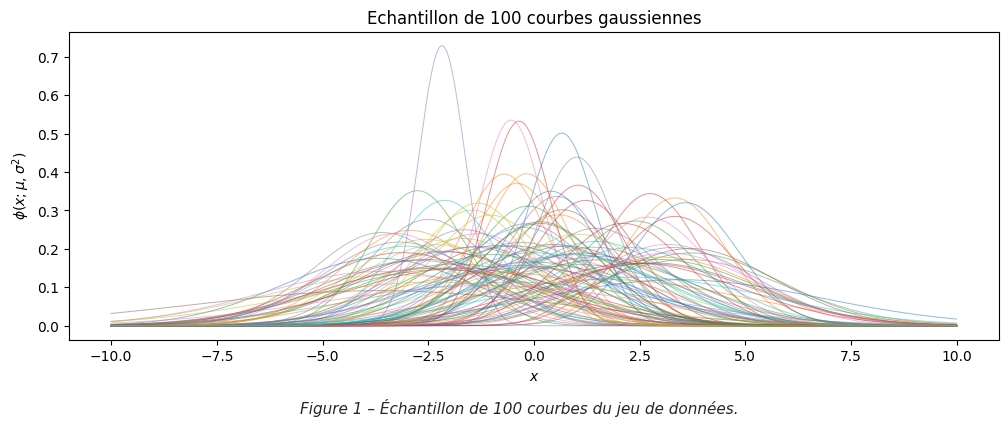

In [4]:
# visualisation d'un echantillon de 100 courbes
from src.visualization import add_caption                                  
fig, ax = plt.subplots(figsize=(12, 4))
for i in np.random.choice(len(y), 100, replace=False):
    ax.plot(x_grid, y[i], lw=0.7, alpha=0.5)
ax.set_xlabel(r'$x$'); ax.set_ylabel(r'$\phi(x; \mu, \sigma^2)$')
ax.set_title('Echantillon de 100 courbes gaussiennes')
add_caption(fig, 'Échantillon de 100 courbes du jeu de données.') 
plt.show()

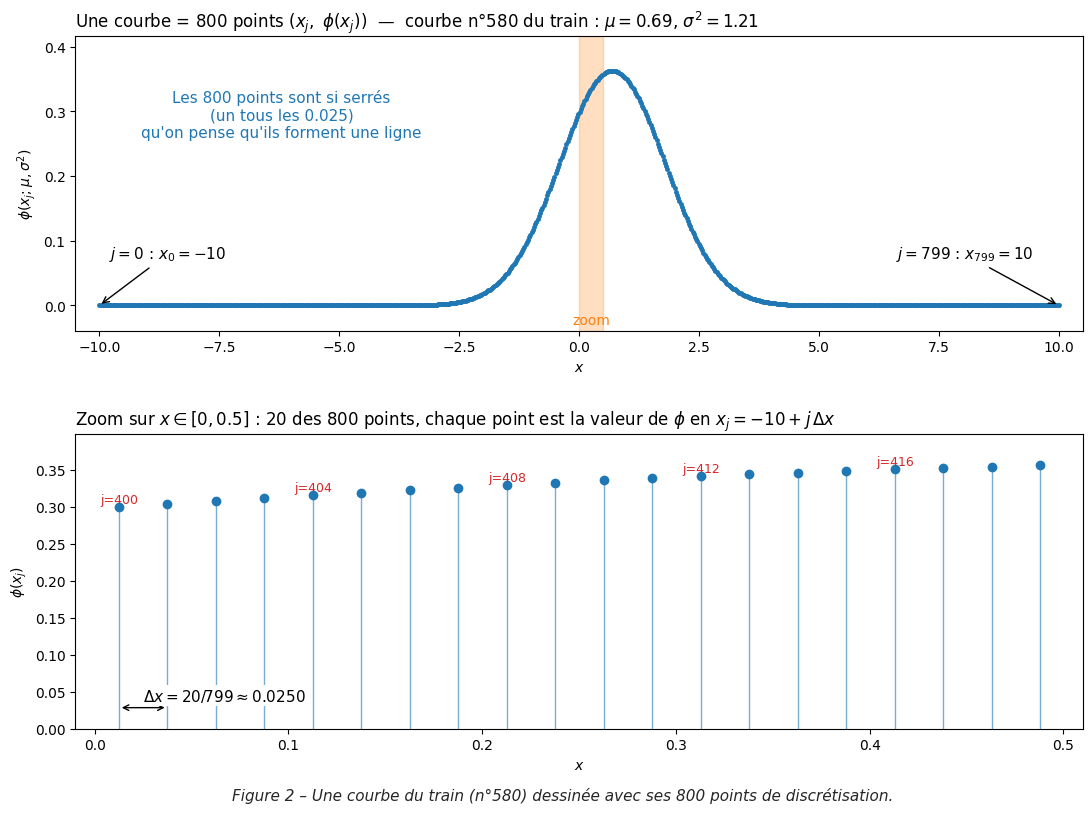

In [5]:
from src.visualization import plot_curve_points, add_caption

i0 = 580   # numéro de la courbe déssinée
fig = plot_curve_points(x_grid, y_train[i0],
                        mu=X_train[i0, 0], var=X_train[i0, 1],
                        name=f'courbe n°{i0} du train')
add_caption(fig, f'Une courbe du train (n°{i0}) dessinée avec ses 800 points de discrétisation.')
plt.show()

### Questions — Partie 0

**Q0.1.** Quelles sont les dimensions respectives de l'espace d'entrée $\mathcal{X}$ et de l'espace de sortie $\mathcal{Y}$ ? Pourquoi une régression directe de $\mathcal{X}$ vers $\mathcal{Y}$ (par un GPR classique, sans espace latent) serait-elle problématique ?

**Q0.2.** Justifiez l'intérêt du découpage train/test. Quelle fraction des données est utilisée pour évaluer le méta-modèle final ?

**Réponse Q0.1 :**
- L'espace d'entrée $\mathcal{X}$ a la forme (2000, 2); chaque ligne est un couple $(\mu, \sigma^2)$ donc de **dimension 2**, avec $\mathcal{X} \subset \mathbb{R}^2$ et $(\mu, \sigma^2) \in [-4, 4] \times \mathbb{R}_+^*$.L'espace de sortie $\mathcal{Y}$ a la forme (2000, 800); chaque ligne est une courbe de 800 points. On peut d'ailleurs voire sur la figure ci-dessus comment est représentée une courbe par ces points. Il est donc de **dimension 800**, avec $\mathcal{Y} \subset \mathbb{R}^{800}$.

- Une régression directe de $\mathcal{X}$ vers $\mathcal{Y}$ par GPR classique serait problématique parce que 800 sorties, c'est lourd, et que ces valeurs sont très liées entre elles. Comme les courbes ne dépendent que de 2 paramètres $(\mu, \sigma^2)$ , il est plus efficace de les compresser d'abord dans un espace latent de petite dimension d, puis de faire la régression vers ce code.


**Réponse Q0.2 :** 
- Le découpage **train/test** mesure **la capacité du méta-modèle à généraliser** à des paramètres $(\mu, \sigma^2)$ qu'il n'a jamais vus.L'apprentissage se fait donc uniquement sur le train et **20 % des données**, soit 400 courbes, servent à évaluer le méta-modèle final.Le tirage aléatoire **(random_state=42)** garantit que les deux ensembles suivent la même loi d'entrée.

## Partie 1 — Réduction de dimension des courbes

Chaque courbe vit dans $\mathbb{R}^{800}$ mais est entièrement déterminée par **2 paramètres**. L'hypothèse de travail est donc qu'elle se concentre près d'une variété de dimension faible. Nous allons comparer plusieurs réducteurs $R : \mathbb{R}^{800} \to \mathbb{R}^d$ (avec reconstruction $R^{-1}$) pour plusieurs valeurs de $d$.

**Critère de comparaison principal** : l'erreur quadratique moyenne de reconstruction sur le jeu de test,

$$\mathrm{EQM}(d) = \frac{1}{n_{\text{test}}}\sum_{i} \big\| y_i - \hat y_i \big\|^2 / M, \qquad \hat y_i = R^{-1}(R(y_i)).$$

> Toutes les classes de réduction doivent proposer une **interface commune** (`fit(Y)`, `transform(Y)`, `inverse_transform(Z)`) afin que le reste du projet soit indépendant de la méthode choisie. Complétez le squelette `src/reduction.py`.

### 1.1 — PCA (scikit-learn)

La PCA est linéaire : c'est la référence à battre. 

Consignes :
1. Complétez la classe `PCAReducer` dans `src/reduction.py` (interface `fit` / `transform` / `inverse_transform`, paramètre `n_components`).
2. Pour $d \in \{1, 2, 3, 5, 10, 20, 50\}$, calculez l'EQM de reconstruction **sur le jeu de test**.
3. Représentez $\mathrm{EQM}(d)$ en échelle semi-log, et superposez la courbe du **ratio de variance expliquée cumulée**.
4. Affichez côte à côte, pour $d = 2$, une courbe test et sa reconstruction PCA.

```python
# --- snippet d'aide (PCA) ---
from sklearn.decomposition import PCA

pca = PCA(n_components=d)
pca.fit(y_train)                       # apprentissage (uniquement sur le train!)
z = pca.transform(y_test)              # projection
y_hat = pca.inverse_transform(z)       # reconstruction
print(pca.explained_variance_ratio_.cumsum())   # variance expliquee cumulee
```

Composantes nécessaires pour 99 % de variance : 10


,variance expliquée cumulée,EQM train,EQM test,rapport test / train
d,,,,
1,54.14%,1.915e-03,2.059e-03,1.07
2,77.77%,9.283e-04,1.058e-03,1.14
3,87.14%,5.371e-04,6.972e-04,1.3
5,94.37%,2.353e-04,3.722e-04,1.58
10,99.16%,3.527e-05,1.463e-04,4.15
20,99.99%,3.236e-07,5.862e-05,181
50,100.00%,6.632e-17,1.286e-06,1.94e+10


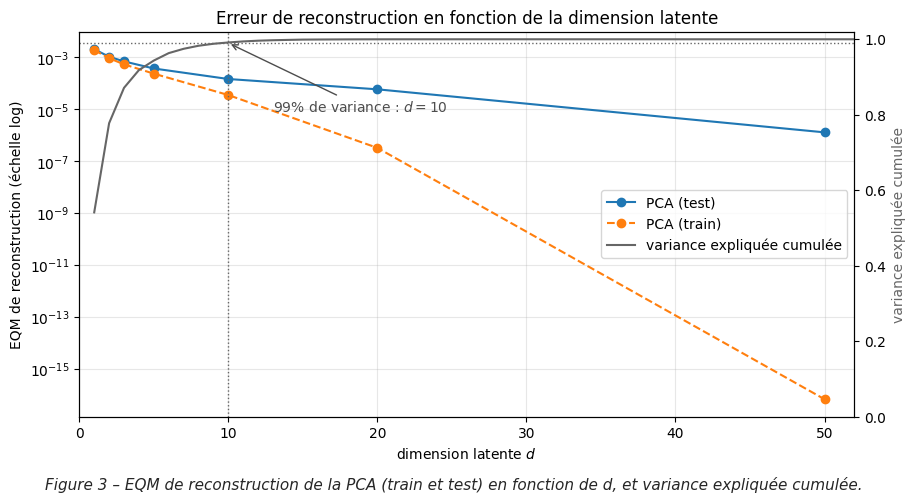

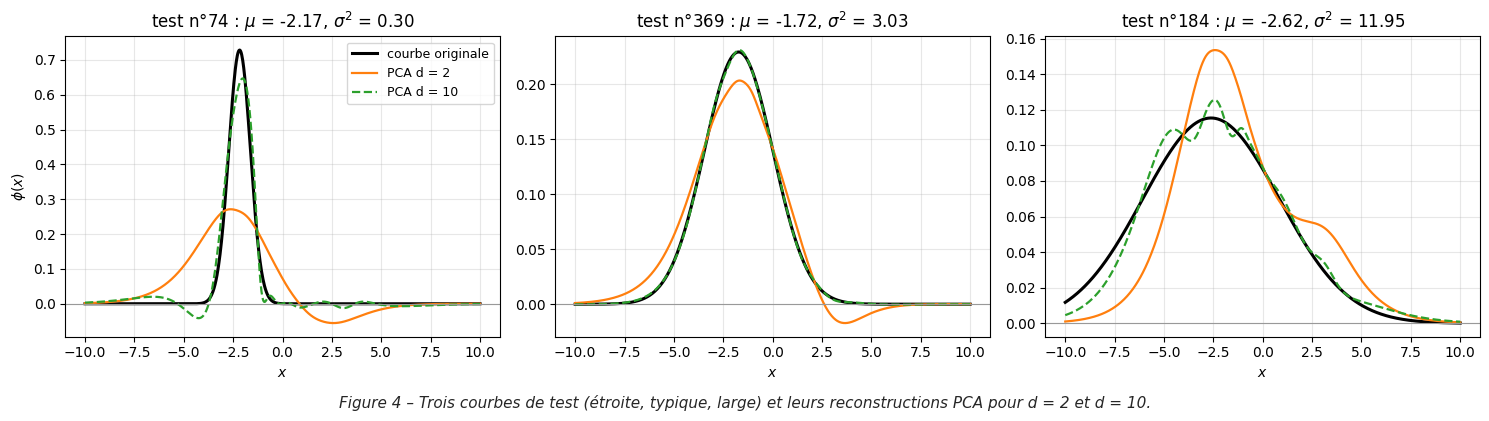

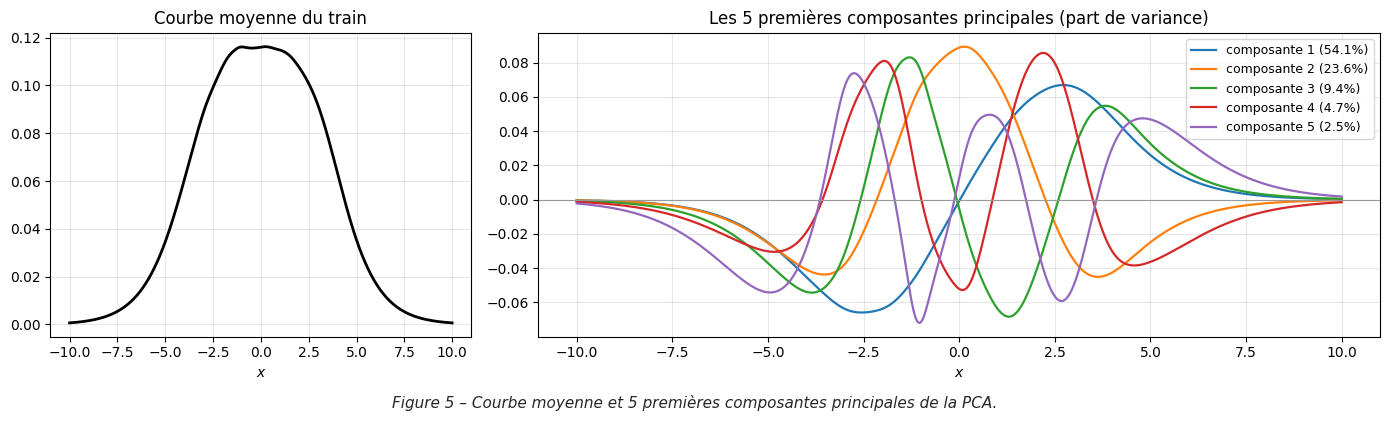

In [6]:
from src.reduction import PCAReducer, reconstruction_mse, cumulative_explained_variance
from src.visualization import mse_table, plot_mse_vs_d, plot_reconstructions, plot_pca_components, add_caption

# 1) EQM de reconstruction pour chaque d, sur le train et sur le test
d_values = [1, 2, 3, 5, 10, 20, 50]
pca_reducers, mse_pca_train, mse_pca_test = {}, [], []
for d in d_values:
    pca = PCAReducer(n_components=d).fit(y_train)     
    pca_reducers[d] = pca
    mse_pca_train.append(reconstruction_mse(pca, y_train))
    mse_pca_test.append(reconstruction_mse(pca, y_test))
    

# 2) Variance expliquée cumulée et nombre de composantes pour 99 %
cum_var = cumulative_explained_variance(y_train, n_max=60)
d_99 = int(np.searchsorted(cum_var, 0.99) + 1)
print(f"Composantes nécessaires pour 99 % de variance : {d_99}")

display(mse_table(d_values, mse_pca_train, mse_pca_test, cum_var=cum_var))

# 3) Courbe EQM(d) + variance cumulée
ax = plot_mse_vs_d({'PCA (test)': (d_values, mse_pca_test),
               'PCA (train)': (d_values, mse_pca_train)}, cum_var=cum_var, threshold=0.99)
add_caption(ax, 'EQM de reconstruction de la PCA (train et test) en fonction de d, '
                'et variance expliquée cumulée.')
plt.show()

# 4) Comparaison visuelle pour d = 2 (et d = 10) : une courbe étroite, une typique, une large
idx = [int(np.argmin(np.abs(X_test[:, 1] - v))) for v in (0.3, 3.0, 12.0)]
titles = [fr'test n°{i} : $\mu$ = {X_test[i, 0]:.2f}, $\sigma^2$ = {X_test[i, 1]:.2f}' for i in idx]
recons = {f'PCA d = {d}': pca_reducers[d].inverse_transform(pca_reducers[d].transform(y_test[idx]))
          for d in (2, 10)}
fig = plot_reconstructions(x_grid, y_test[idx], recons, titles=titles)
add_caption(fig, 'Trois courbes de test (étroite, typique, large) et leurs reconstructions '
                 'PCA pour d = 2 et d = 10.')
plt.show()

# 5) Complément : les « courbes de base » de la PCA
fig = plot_pca_components(x_grid, pca_reducers[5], n_components=5)
add_caption(fig, 'Courbe moyenne et 5 premières composantes principales de la PCA.')
plt.show()

**Q1.1.** Combien de composantes la PCA nécessite-t-elle pour expliquer 99 % de la variance ? Ce nombre est-il cohérent avec la dimension de l'espace des paramètres (2) ? Interprétez l'écart.

**Q1.2.** La PCA est-il un candidat satisfaisant pour le méta-modèle ? Quel est son défaut principal ici ?

**Réponse Q1.1 :**
- La PCA nécessite **10 composantes** pour expliquer 99 % de la variance. Avec $d = 2$, elle n'en explique que **77,77%**, alors que les courbes ne dépendent que de 2 paramètres. Ce n'est donc pas cohérent avec la dimension intrinsèque.

- Cet écart est dû au fait que la PCA cherche **le meilleur sous-espace linéaire**, alors que les courbes forment **une surface courbe de dimension 2** dans $\mathbb{R}^{800}$ : faire varier $\mu$ translate la cloche, ce qui n'est pas une opération linéaire. Pour suivre cette surface avec des combinaisons linéaires, la PCA **doit empiler des composantes de plus en plus oscillantes** (voir la figure des composantes). Elle nécessite donc beaucoup plus de dimensions **(≈ 10 au lieu de 2)** pour représenter correctement les courbes.


**Réponse Q1.2 :**
- La PCA est rapide, déterministe, et possède un décodeur exact et linéaire. C'est une bonne référence, mais **pas un candidat satisfaisant pour un espace latent compact**. **Son défaut principal est sa linéarité** : aux petites dimensions ($d = 2$ ou $3$), les reconstructions sont fausses et non physiques. On voit sur la **Figure 4** que les courbes reconstruites avec $d = 2$ n'ont pas les mêmes pics que les courbes originales (le pic de la courbe étroite passe de 0,73 à 0,27) et qu'elles descendent sous 0, ce qui est impossible pour une densité. Or ces erreurs sur la hauteur du pic faussent directement l'estimation de $\mathbb{P}(\phi \geq \tau)$.

Pour être précise, la PCA doit monter à $d \geq 10$–$20$. La GPR devra alors prédire 10 à 20 codes, dont les derniers correspondent aux composantes les plus oscillantes et seront probablement plus difficiles à apprendre.

### 1.2 — Autoencodeur dense (PyTorch *ou* tensorflow)

Un autoencodeur apprend une réduction **non linéaire** : encodeur $g_\phi : \mathbb{R}^{800} \to \mathbb{R}^d$, décodeur $f_\theta : \mathbb{R}^d \to \mathbb{R}^{800}$, entraînés conjointement par erreur de reconstruction (MSE).

**Indiquez ici votre choix de librairie** : ☐ PyTorch ☑ **tensorflow** (Keras)

Consignes :
1. Complétez la classe `AutoEncoderReducer` dans `src/reduction.py`. Architecture suggérée (à adapter) : `800 → 128 → 64 → d → 64 → 128 → 800`, activation SiLU/ReLU, sortie linéaire, loss MSE, optimiseur Adam ($10^{-3}$), early stopping sur la validation, `batch_size = 64`.
2. Entraînez pour $d \in \{2, 3, 5, 10, 20\}$ ; stockez à chaque fois l'EQM test de reconstruction.
3. Tracez $\mathrm{EQM}_{\text{AE}}(d)$ et superposez la courbe PCA de la question 1.1.
4. Pour $d = 2$ : visualisez l'espace latent (codes des courbes de train, colorés par $\mu$ puis par $\sigma^2$) et commentez l'organisation obtenue.

```python
# --- squelette PyTorch (si vous choisissez PyTorch) ---
import torch, torch.nn as nn

class Encoder(nn.Module):
    def __init__(self, nbx=800, nbz=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(nbx, 128), nn.SiLU(),
            nn.Linear(128, 64),  nn.SiLU(),
            nn.Linear(64, nbz),
        )
    def forward(self, x):
        return self.net(x)

class Decoder(nn.Module):   # symetrique de l'encodeur
    ...

# boucle d'entrainement : descente de gradient sur la MSE,
# jeu de validation = 20 % du train, early stopping.
```

d =  2 : 300 époques, 137 s
d =  3 : 300 époques, 141 s
d =  5 : 300 époques, 117 s
d = 10 : 300 époques, 81 s
d = 20 : 300 époques, 95 s


,EQM PCA,EQM AE,facteur PCA / AE,temps PCA (s),temps AE (s)
d,,,,,
2,1.058e-03,1.663e-04,6.4,3.00,137
3,6.972e-04,1.564e-04,4.5,2.93,141
5,3.722e-04,1.525e-04,2.4,0.60,117
10,1.463e-04,1.369e-04,1.1,0.91,81
20,5.862e-05,1.305e-04,0.4,0.64,95


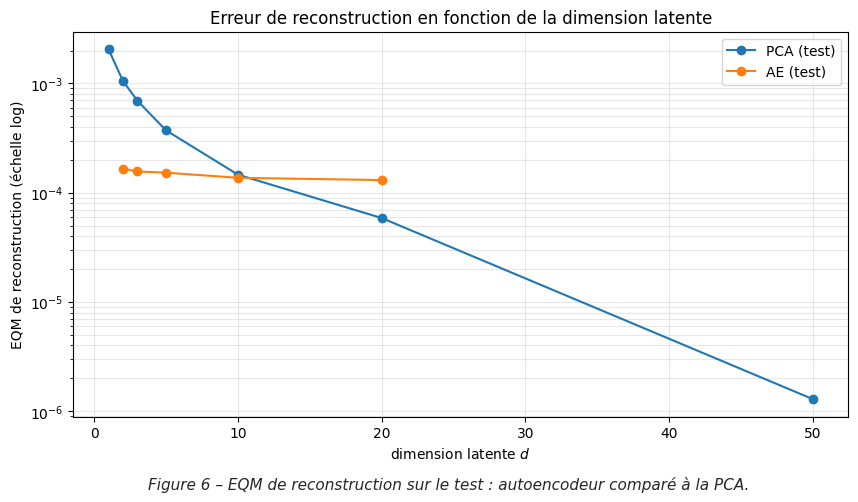

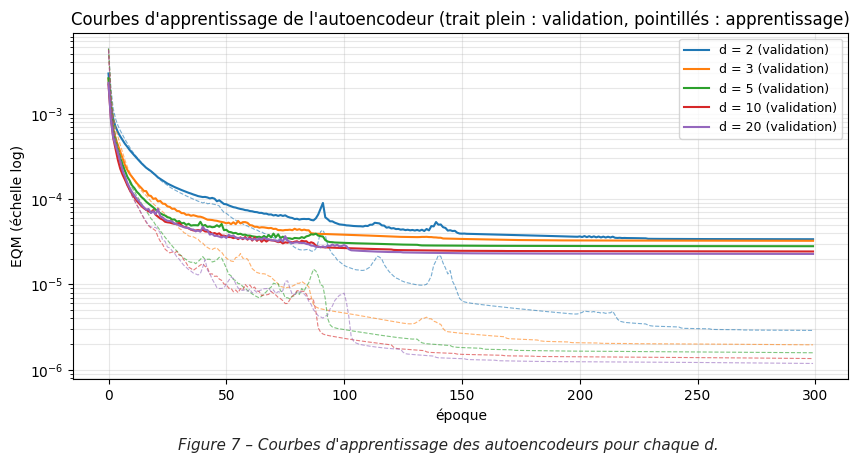

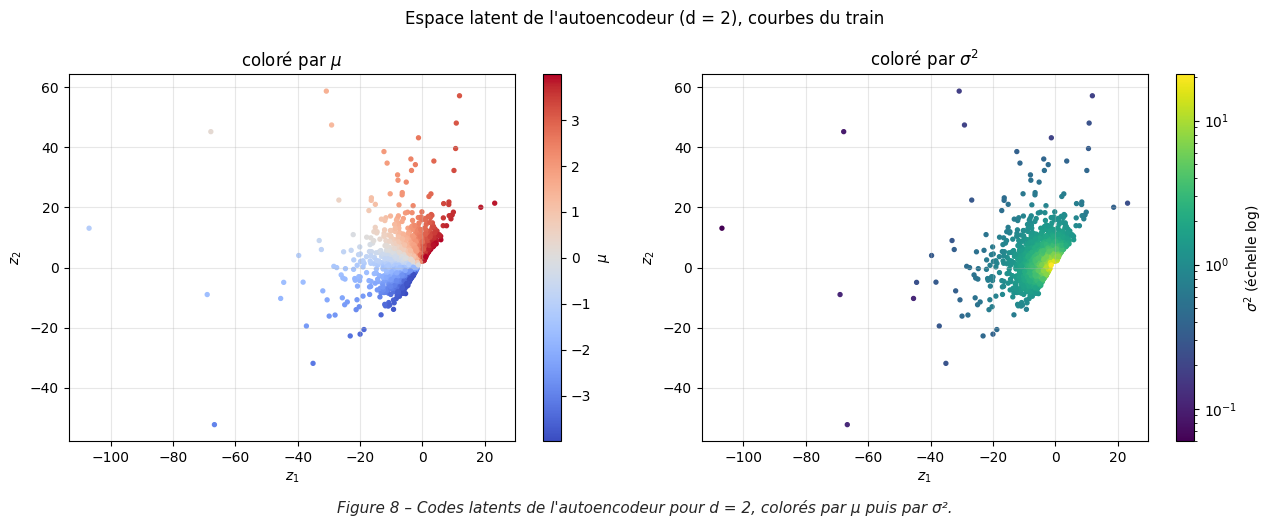

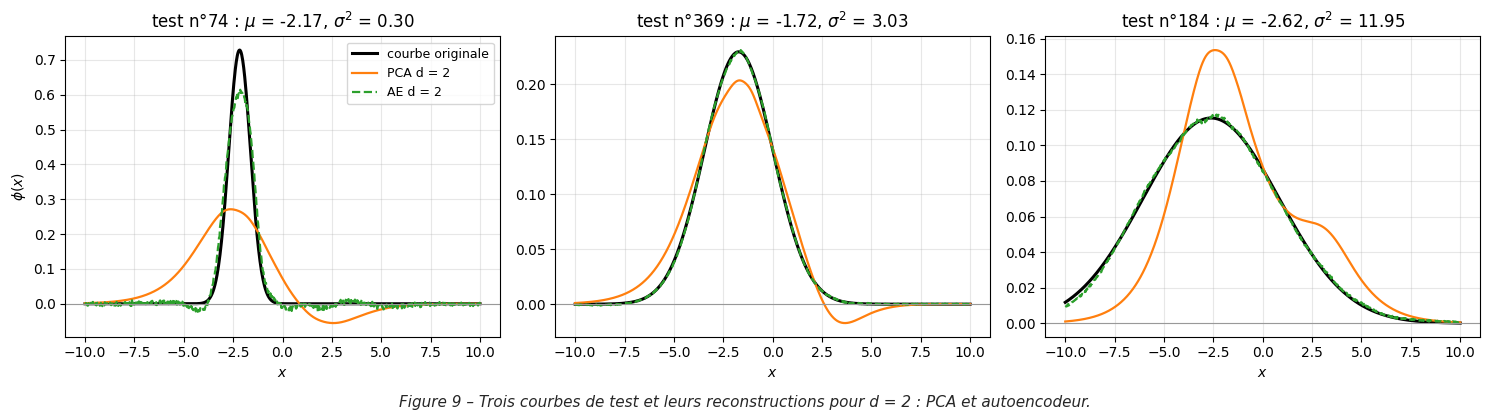

In [7]:
import time
from src.reduction import AutoEncoderReducer
from src.visualization import (compare_table, plot_mse_vs_d, plot_training_history,
                               plot_latent_space, plot_reconstructions, add_caption)

# 1) Entraînement de l'AE pour chaque d (+ PCA aux mêmes d pour comparer)
d_values_ae = [2, 3, 5, 10, 20]
ae_reducers, mse_ae_test, time_ae = {}, [], []
mse_pca_ae, time_pca = [], []
for d in d_values_ae:
    ae = AutoEncoderReducer(nbx=M, latent_dim=d, epochs=300, batch_size=64, seed=42).fit(y_train)
    ae_reducers[d] = ae
    mse_ae_test.append(reconstruction_mse(ae, y_test))
    time_ae.append(ae.fit_time_)
    t0 = time.perf_counter()
    pca = PCAReducer(n_components=d).fit(y_train)
    time_pca.append(time.perf_counter() - t0)
    mse_pca_ae.append(reconstruction_mse(pca, y_test))
    print(f"d = {d:2d} : {ae.n_epochs_} époques, {ae.fit_time_:.0f} s")

display(compare_table(d_values_ae, mse_pca_ae, mse_ae_test, time_pca=time_pca, time_ae=time_ae))

# 2) EQM_AE(d) superposée à la courbe PCA
ax = plot_mse_vs_d({'PCA (test)': (d_values, mse_pca_test),
                    'AE (test)': (d_values_ae, mse_ae_test)})
add_caption(ax, "EQM de reconstruction sur le test : autoencodeur comparé à la PCA.")
plt.show()

# 3) Courbes d'apprentissage (coût d'entraînement)
ax = plot_training_history({d: ae_reducers[d].history_ for d in d_values_ae})
add_caption(ax, "Courbes d'apprentissage des autoencodeurs pour chaque d.")
plt.show()

# 4) Espace latent pour d = 2, coloré par mu puis par sigma^2
fig = plot_latent_space(ae_reducers[2].transform(y_train), X_train,
                        title="Espace latent de l'autoencodeur (d = 2), courbes du train")
add_caption(fig, "Codes latents de l'autoencodeur pour d = 2, colorés par μ puis par σ².")
plt.show()

# 5) Reconstructions pour d = 2 : PCA et AE sur les mêmes courbes de test
idx = [int(np.argmin(np.abs(X_test[:, 1] - v))) for v in (0.3, 3.0, 12.0)]
titles = [fr'test n°{i} : $\mu$ = {X_test[i, 0]:.2f}, $\sigma^2$ = {X_test[i, 1]:.2f}' for i in idx]
recons = {'PCA d = 2': pca_reducers[2].inverse_transform(pca_reducers[2].transform(y_test[idx])),
          'AE d = 2': ae_reducers[2].inverse_transform(ae_reducers[2].transform(y_test[idx]))}
fig = plot_reconstructions(x_grid, y_test[idx], recons, titles=titles)
add_caption(fig, "Trois courbes de test et leurs reconstructions pour d = 2 : PCA et autoencodeur.")
plt.show()

**Q1.3.** Comparez quantitativement PCA et autoencodeur : pour quelles dimensions $d$ l'AE bat-il la PCA, et par quel facteur ? Que dire du compromis précision / coût d'entraînement ?

**Réponse Q1.3 :**

**Comparaison quantitative.** L'autoencodeur bat la PCA aux petites dimensions : son EQM test est $6{,}4$ fois plus faible à $d = 2$, $4{,}5$ fois à $d = 3$ et $2{,}4$ fois à $d = 5$. Les deux méthodes sont équivalentes à $d = 10$ (facteur $1{,}1$), et la PCA reprend l'avantage à $d = 20$ (EQM $2{,}2$ fois plus faible que l'AE).

L'erreur de l'AE dépend très peu de $d$ (de $1{,}7 \cdot 10^{-4}$ à $d = 2$ à $1{,}3 \cdot 10^{-4}$ à $d = 20$) : grâce à sa non-linéarité, il décrit déjà la surface des courbes avec 2 dimensions, la dimension intrinsèque du problème. Son erreur restante est limitée par la taille du réseau et par l'entraînement plutôt que par $d$ : les 5 entraînements ont atteint la limite de 300 époques sans déclencher l'early stopping, donc un entraînement plus long pourrait encore l'améliorer. Ainsi, **l'AE à $d = 2$ est aussi précis qu'une PCA à $d = 10$** ($1{,}66 \cdot 10^{-4}$ contre $1{,}46 \cdot 10^{-4}$).

**Compromis précision / coût.** L'AE demande 64 à 70 s d'entraînement, contre moins de 1 s pour la PCA (environ 70 à 120 fois plus). Mais ce coût n'est payé qu'une fois, hors ligne, et reste négligeable devant un seul appel au simulateur, supposé très couteux. Pour le méta-modèle, l'AE à petit $d$ est donc le meilleur compromis : la GPR n'aura que 2 codes à prédire, au lieu d'une dizaine avec la PCA pour une précision comparable.

**Choix de TensorFlow / Keras.** L'API de haut niveau (`compile` / `fit`) évite d'écrire la boucle d'entraînement. L'early stopping et la réduction du pas d'apprentissage sont fournis directement sous forme de *callbacks*. Le décodeur se définit comme un sous-modèle séparé, donc réutilisable seul en Parties 2 et 3. Enfin, toutes les graines se fixent en une ligne (`keras.utils.set_random_seed`).

### 1.3 — *(Bonus)* Autres méthodes de réduction

Pour aller plus loin, vous pouvez comparer avec :

- **Kernel PCA** (`sklearn.decomposition.KernelPCA`, noyau `rbf`) — non linéaire, mais le choix du noyau et de `gamma` est délicat ;
- **t-SNE / UMAP** — excellentes pour la visualisation, mais **pas de `inverse_transform`** : discutez de la conséquence pour un méta-modèle ;
- **Autoencodeur variationnel (VAE)** — espace latent probabiliste régularisé (module `src/` du démonstrateur d'enseignant, mentionné à titre indicatif).

```python
# --- snippet d'aide ---
from sklearn.decomposition import KernelPCA
kpca = KernelPCA(n_components=d, kernel='rbf', gamma=0.05, fit_inverse_transform=True)
```

d =  2 : gamma = 0.02, alpha = 1e-07, EQM test = 4.882e-04, ajustement 1.49 s
d =  3 : gamma = 0.02, alpha = 1e-07, EQM test = 3.548e-04, ajustement 1.36 s
d =  5 : gamma = 0.01, alpha = 1e-07, EQM test = 2.510e-04, ajustement 1.57 s
d = 10 : gamma = 0.01, alpha = 1e-07, EQM test = 1.581e-04, ajustement 1.11 s
d = 20 : gamma = 0.01, alpha = 1e-07, EQM test = 9.198e-05, ajustement 1.06 s


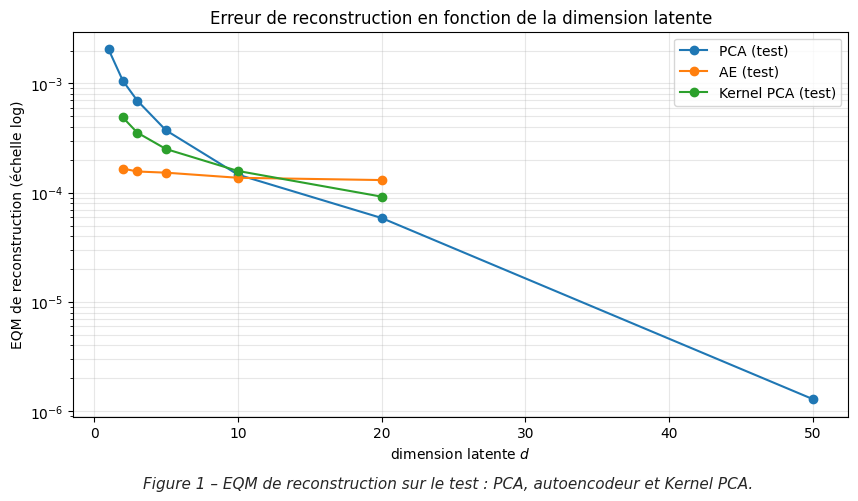

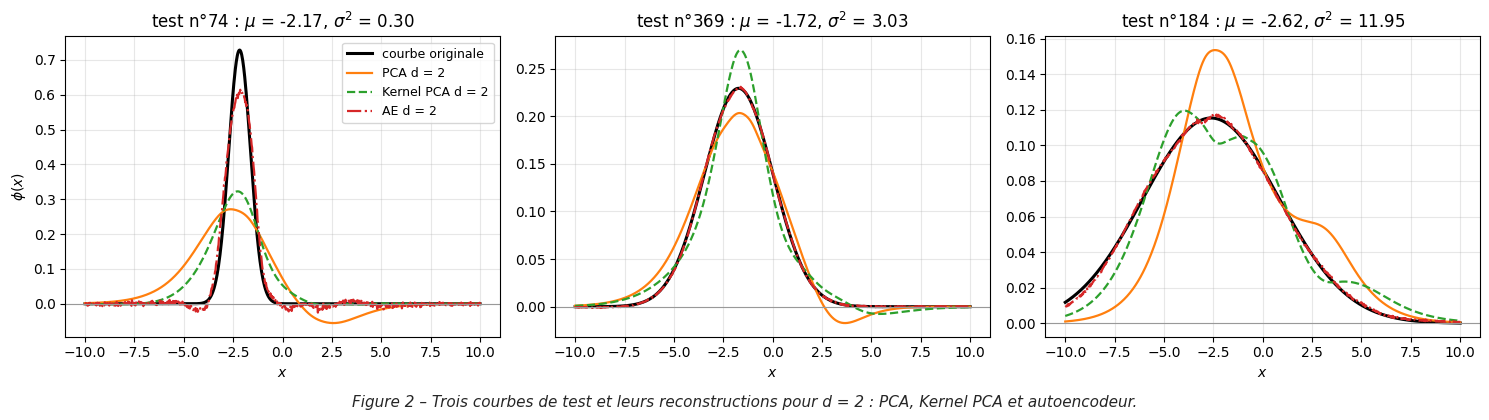

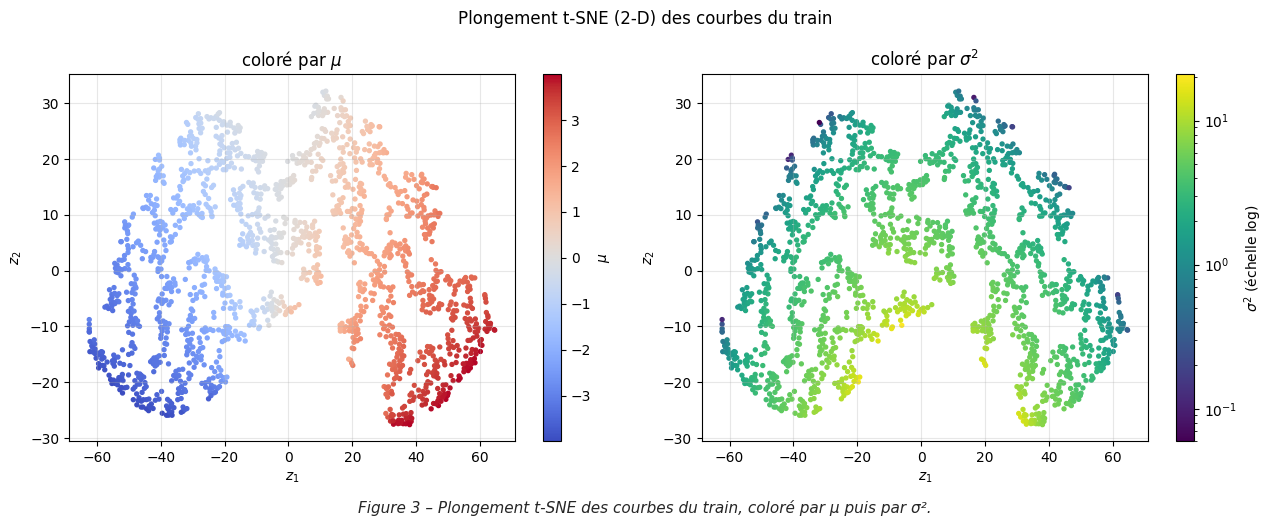

,type,EQM test d=2,EQM test d=5,EQM test d=10,temps entraînement d=2 (s),encode de nouvelles courbes,décodeur z → courbe,utilisable dans le pipeline
méthode,,,,,,,,
PCA,linéaire,1.06e-03,3.72e-04,1.46e-04,1.3,oui,oui (exact),oui
Kernel PCA (RBF),non linéaire (noyau),4.88e-04,2.51e-04,1.58e-04,1.5,oui,"oui (appris, approché)",oui
Autoencodeur,non linéaire (réseau),1.66e-04,1.53e-04,1.37e-04,137.1,oui,oui (réseau décodeur),oui
t-SNE,non linéaire (voisinages),—,—,—,15.3,non,non,non


In [8]:
import time
from sklearn.manifold import TSNE
from src.reduction import tune_kernel_pca
from src.visualization import (models_table, plot_mse_vs_d, plot_latent_space,
                               plot_reconstructions, add_caption)

# 1) Kernel PCA (noyau RBF) : gamma et alpha choisis sur une validation tirée du train
kpca_reducers, mse_kpca_test = {}, []
for d in d_values_ae:
    kpca, scores = tune_kernel_pca(y_train, n_components=d)
    kpca_reducers[d] = kpca
    mse_kpca_test.append(reconstruction_mse(kpca, y_test))
    print(f"d = {d:2d} : gamma = {kpca.gamma:g}, alpha = {kpca.alpha:g}, "
          f"EQM test = {mse_kpca_test[-1]:.3e}, ajustement {kpca.fit_time_:.2f} s")

# 2) EQM(d) des trois méthodes qui savent reconstruire
ax = plot_mse_vs_d({'PCA (test)': (d_values, mse_pca_test),
                    'AE (test)': (d_values_ae, mse_ae_test),
                    'Kernel PCA (test)': (d_values_ae, mse_kpca_test)})
add_caption(ax, "EQM de reconstruction sur le test : PCA, autoencodeur et Kernel PCA.")
plt.show()

# 3) Reconstructions pour d = 2 (mêmes courbes de test qu'en 1.1 et 1.2)
recons = {f'{nom} d = 2': r.inverse_transform(r.transform(y_test[idx]))
          for nom, r in [('PCA', pca_reducers[2]), ('Kernel PCA', kpca_reducers[2]),
                         ('AE', ae_reducers[2])]}
fig = plot_reconstructions(x_grid, y_test[idx], recons, titles=titles)
add_caption(fig, "Trois courbes de test et leurs reconstructions pour d = 2 : "
                 "PCA, Kernel PCA et autoencodeur.")
plt.show()

# 4) t-SNE : plongement 2-D des courbes du train (visualisation seulement)
t0 = time.perf_counter()
Z_tsne = TSNE(n_components=2, init='pca', random_state=42).fit_transform(y_train)
time_tsne = time.perf_counter() - t0
fig = plot_latent_space(Z_tsne, X_train, title="Plongement t-SNE (2-D) des courbes du train")
add_caption(fig, "Plongement t-SNE des courbes du train, coloré par μ puis par σ².")
plt.show()

# 5) Tableau comparatif des modèles
pca_d = dict(zip(d_values, mse_pca_test))
ae_d = dict(zip(d_values_ae, mse_ae_test))
kpca_d = dict(zip(d_values_ae, mse_kpca_test))
records = [
    {'méthode': 'PCA', 'type': 'linéaire',
     'EQM test d=2': pca_d[2], 'EQM test d=5': pca_d[5], 'EQM test d=10': pca_d[10],
     'temps entraînement d=2 (s)': pca_reducers[2].fit_time_,
     'encode de nouvelles courbes': 'oui', 'décodeur z → courbe': 'oui (exact)',
     'utilisable dans le pipeline': 'oui'},
    {'méthode': 'Kernel PCA (RBF)', 'type': 'non linéaire (noyau)',
     'EQM test d=2': kpca_d[2], 'EQM test d=5': kpca_d[5], 'EQM test d=10': kpca_d[10],
     'temps entraînement d=2 (s)': kpca_reducers[2].fit_time_,
     'encode de nouvelles courbes': 'oui', 'décodeur z → courbe': 'oui (appris, approché)',
     'utilisable dans le pipeline': 'oui'},
    {'méthode': 'Autoencodeur', 'type': 'non linéaire (réseau)',
     'EQM test d=2': ae_d[2], 'EQM test d=5': ae_d[5], 'EQM test d=10': ae_d[10],
     'temps entraînement d=2 (s)': ae_reducers[2].fit_time_,
     'encode de nouvelles courbes': 'oui', 'décodeur z → courbe': 'oui (réseau décodeur)',
     'utilisable dans le pipeline': 'oui'},
    {'méthode': 't-SNE', 'type': 'non linéaire (voisinages)',
     'EQM test d=2': None, 'EQM test d=5': None, 'EQM test d=10': None,
     'temps entraînement d=2 (s)': time_tsne,
     'encode de nouvelles courbes': 'non', 'décodeur z → courbe': 'non',
     'utilisable dans le pipeline': 'non'},
]
display(models_table(records))

**Q1.4.** *(Bonus)* Le Kernel PCA améliore-t-il la reconstruction ? Qu'en est-il du coût de calcul ? Pourquoi t-SNE/UMAP ne peuvent-ils pas être utilisés tels quels dans le pipeline (pensez à l'étape GPR → décodeur) ?

**Réponse Q1.4 :**

**Kernel PCA.** Elle améliore la reconstruction par rapport à la PCA aux petites dimensions : EQM test de $4{,}9 \cdot 10^{-4}$ contre $1{,}06 \cdot 10^{-3}$ à $d = 2$ ($2{,}2$ fois moins), et $1{,}5$ fois moins à $d = 5$. L'avantage disparaît à $d \geq 10$, et elle reste environ 3 fois moins précise que l'autoencodeur à $d = 2$.

Son ajustement est rapide (≈ **1,1 s**, comparable à la PCA et bien moins que les 64 à 70 s de l'AE), mais elle a un inconvénient majeur : **son coût croît fortement avec le nombre $n$ de courbes d'entraînement**. Il faut stocker **une matrice $n \times n$**, la diagonalisation coûte **$O(n^3)$**, et chaque encodage ou décodage nécessite de comparer le point aux $n$ courbes du train.

**Pourquoi on ne peut pas utiliser t-SNE / UMAP ?** Parce que le pipeline exige deux opérations : prédire un code $z$ à partir de $(\mu, \sigma^2)$, puis **décoder** $z$ en courbe. Or t-SNE ne calcule qu'un plongement des données d'entraînement (`fit_transform`) : il ne sait ni encoder une nouvelle courbe (pas de `transform`), ni surtout reconstruire une courbe à partir d'un point de l'espace latent (pas d'`inverse_transform`). Le $z$ prédit par la GPR ne pourrait donc jamais être transformé en courbe. De plus, t-SNE ne préserve que les voisinages locaux, pas les distances : ses coordonnées varient d'une exécution à l'autre et ne forment pas une fonction régulière de $(\mu, \sigma^2)$. UMAP propose un `transform` et un `inverse_transform`, mais ce dernier n'est qu'une approximation par interpolation entre points d'entraînement, sans garantie de régularité. Ces méthodes conviennent à la visualisation, pas au rôle de décodeur d'un méta-modèle.

## Partie 2 — Régression GPR dans l'espace latent

On apprend maintenant la régression **entrées → codes latents** :

$$\psi : (\mu, \sigma^2) \in \mathbb{R}^2 \;\longrightarrow\; \mathbf{z} \in \mathbb{R}^d,$$

par un **processus gaussien multi-sorties** (une GPR indépendante par dimension latente, ou une seule GPR sur les $d$ sorties). Complétez le squelette `src/gpr_model.py`.

Consignes :
1. **Noyaux à comparer** : `RBF`, `Matern(2.5)`, `RationalQuadratic`, chacun multiplié par `ConstantKernel` et additionné d'un `WhiteKernel` (bruit). 
2. **Optimisation des hyperparamètres** : laisser `GaussianProcessRegressor` maximiser la log-vraisemblance marginale, avec `n_restarts_optimizer` redémarrages pour éviter les maxima locaux ; justifier le nombre de redémarrages choisi.
3. Pour **chaque réducteur** retenu en Partie 1 (au minimum AE avec votre meilleur $d$) et **chaque noyau** : entraînez la GPR sur le train, puis
   - mesurez l'erreur dans l'espace latent : $\mathrm{RMSE}_z = \sqrt{\mathrm{MSE}(\hat{\mathbf z}, \mathbf z)}$ sur le test ;
   - **décodez** les prédictions $\hat{\mathbf z}$ et mesurez l'EQM de courbe correspondante sur le test.

```python
# --- snippet d'aide : grille de noyaux ---
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, ConstantKernel as C, WhiteKernel

kernels = {
    "RBF":   C(1.0) * RBF(1.0)            + WhiteKernel(1e-3),
    "Matern": C(1.0) * Matern(nu=2.5)     + WhiteKernel(1e-3),
    "RQ":    C(1.0) * RationalQuadratic() + WhiteKernel(1e-3),
}
gpr = GaussianProcessRegressor(kernel=kernels["RBF"], alpha=1e-5,
                               n_restarts_optimizer=3, normalize_y=True)
gpr.fit(X_train, Z_train)          # Z_train : codes latents du train, shape (n_train, d)
Z_pred, Z_std = gpr.predict(X_test, return_std=True)
```

Z_train : (1600, 2) | Z_test : (400, 2)


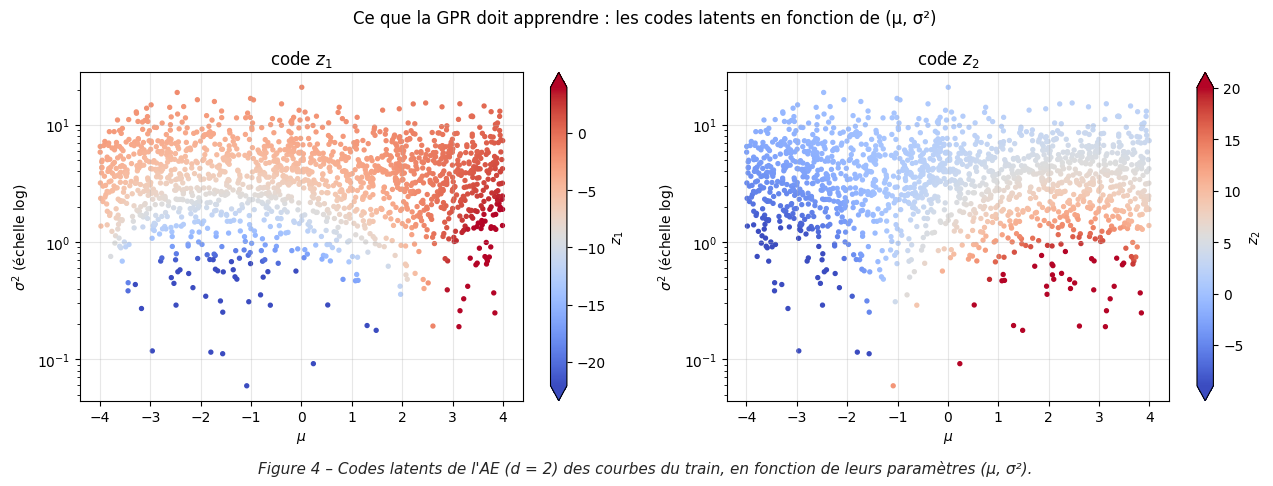

In [9]:
from src.visualization import plot_codes_vs_params, add_caption

ae2 = ae_reducers[2]                 # réducteur retenu en Partie 1 : AE, d = 2
Z_train = ae2.transform(y_train)     # codes des courbes du train
Z_test = ae2.transform(y_test)       # codes des courbes du test
print('Z_train :', Z_train.shape, '| Z_test :', Z_test.shape)

fig = plot_codes_vs_params(X_train, Z_train)
add_caption(fig, "Codes latents de l'AE (d = 2) des courbes du train, en fonction de leurs paramètres (μ, σ²).")
plt.show()

**Comment lire la figure ci-dessus?**

Avant de passer à l'entrainement de la GPR il faut d'abord regarder ce que la GPR doit apprendre : les codes z en fonction de $(\mu, \sigma^2)$

- Pour $\sigma^2$ > 1 (la majorité des courbes), les couleurs changent doucement et régulièrement. Cette zone sera facile à apprendre pour la GPR.
- Pour $\sigma^2$ < 1 **(courbes étroites)**, les couleurs deviennent extrêmes : les codes changent brutalement, et il y a très peu de points. C'est là que **la GPR aura du mal : peu d'exemples, et une fonction qui varie vite.**

**L'axe $\sigma^2$ est en échelle logarithmique**. C'est ce qui rend la **zone des petites $\sigma^2$ lisible**.

In [10]:
from src.gpr_model import fit_gpr, latent_rmse, latent_rmse_relative, decoded_curve_mse

gpr_rbf = fit_gpr(X_train, Z_train, kernel_name='RBF', n_restarts=0)
print('Noyau optimisé :', gpr_rbf.kernel_)
print(f"Temps d'ajustement : {gpr_rbf.fit_time_:.0f} s\n")

print(f"RMSE latente           : {latent_rmse(gpr_rbf, X_test, Z_test):.3f}")
print(f"RMSE latente relative  : {latent_rmse_relative(gpr_rbf, X_test, Z_test):.3f}")
print(f"EQM reconstruction (AE seul, sans GPR) : {reconstruction_mse(ae2, y_test):.3e}")
print(f"EQM décodée (GPR + décodeur)           : {decoded_curve_mse(gpr_rbf, ae2.decoder, X_test, y_test):.3e}")

Noyau optimisé : 1.58**2 * RBF(length_scale=[0.476, 0.692]) + WhiteKernel(noise_level=1e-10)
Temps d'ajustement : 43 s

RMSE latente           : 1.982
RMSE latente relative  : 0.299
EQM reconstruction (AE seul, sans GPR) : 1.663e-04
EQM décodée (GPR + décodeur)           : 2.443e-04


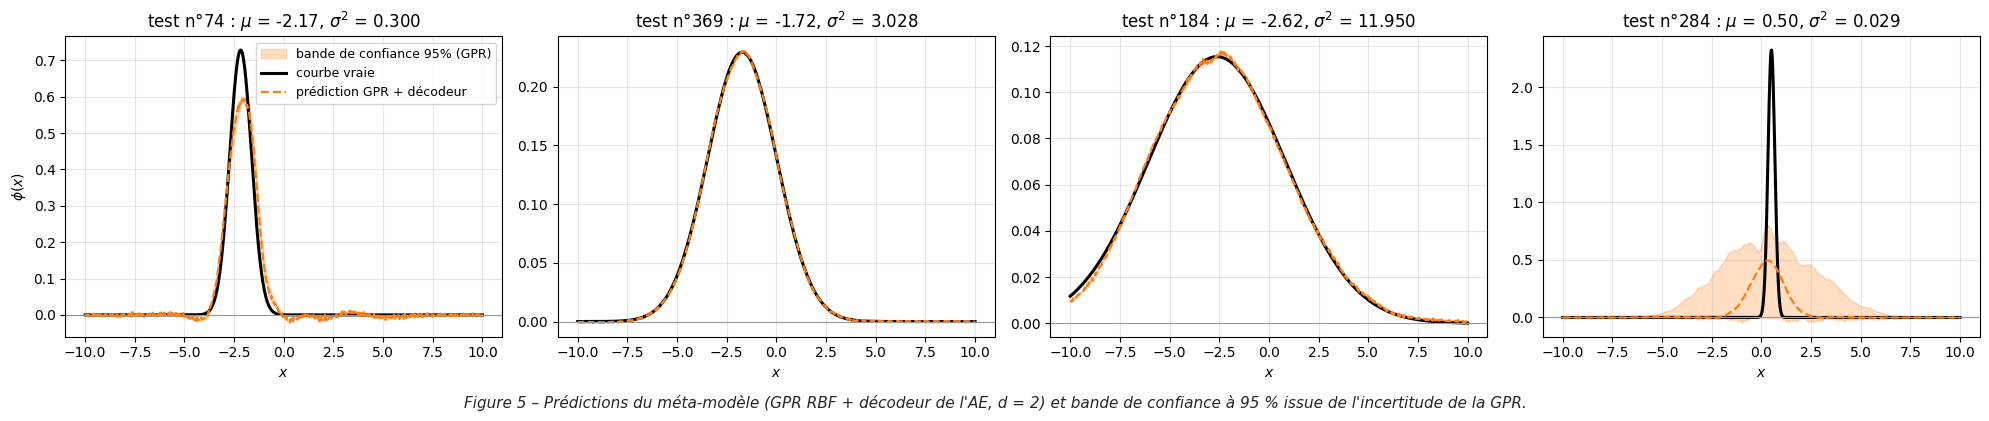

In [11]:
from src.gpr_model import predict_curves_with_band
from src.visualization import plot_gpr_predictions

idx2 = idx + [int(np.argmin(X_test[:, 1]))]
titles2 = [fr'test n°{i} : $\mu$ = {X_test[i, 0]:.2f}, $\sigma^2$ = {X_test[i, 1]:.3f}' for i in idx2]
y_pred, y_lo, y_hi = predict_curves_with_band(gpr_rbf, ae2.decoder, X_test[idx2])
fig = plot_gpr_predictions(x_grid, y_test[idx2], y_pred, y_lo, y_hi, titles=titles2)
add_caption(fig, "Prédictions du méta-modèle (GPR RBF + décodeur de l'AE, d = 2) et bande de "
                 "confiance à 95 % issue de l'incertitude de la GPR.")
plt.show()

**Première GPR (noyau RBF, AE $d = 2$).**  Sur le test, la RMSE latente vaut $1{,}98$, soit $0{,}30$ fois l'écart-type des codes, et l'EQM de courbe après décodage vaut $2{,}44 \cdot 10^{-4}$, contre $1{,}66 \cdot 10^{-4}$ pour la reconstruction par l'AE seul : la GPR ajoute environ 47 % d'erreur, l'essentiel restant dû au décodeur.

La bande de confiance à 95 % est très fine pour les courbes typiques et larges, bien prédites. Elle s'élargit fortement pour la courbe $\sigma^2 = 0{,}029$, hors de la plage du train : la GPR signale qu'elle extrapole. Cette bande ne traduit toutefois que l'incertitude sur $z$, pas les limites du décodeur : le pic de la courbe étroite ($\sigma^2 = 0{,}3$) est sous-estimé alors que la bande reste fine.

In [12]:
from src.gpr_model import decoded_curve_errors
from src.visualization import results_table

gpr_models = {'RBF': gpr_rbf}                      # déjà entraîné à l'étape 2
for k in ['Matern', 'RQ']:
    gpr_models[k] = fit_gpr(X_train, Z_train, kernel_name=k, n_restarts=0)

gpr_records, gpr_errors = [], {}
for k, gpr in gpr_models.items():
    gpr_errors[k] = decoded_curve_errors(gpr, ae2.decoder, X_test, y_test)   # EQM de chaque courbe de test
    gpr_records.append({'noyau': k,
                        'RMSE latente': latent_rmse(gpr, X_test, Z_test),
                        'RMSE latente relative': latent_rmse_relative(gpr, X_test, Z_test),
                        'EQM décodée': gpr_errors[k].mean(),
                        'temps GPR (s)': gpr.fit_time_,
                        'noyau optimisé': str(gpr.kernel_)})
display(results_table(gpr_records, index='noyau'))

,RMSE latente,RMSE latente relative,EQM décodée,temps GPR (s),noyau optimisé
noyau,,,,,
RBF,1.982e+00,2.986e-01,2.443e-04,42.5,"1.58**2 * RBF(length_scale=[0.476, 0.692]) + WhiteKernel(noise_level=1e-10)"
Matern,3.113e+00,4.691e-01,2.559e-04,33.3,"23.8**2 * Matern(length_scale=[4.25, 8.91], nu=2.5) + WhiteKernel(noise_level=1e-10)"
RQ,2.461e+00,3.709e-01,2.893e-04,49.8,"6.25**2 * RationalQuadratic(alpha=0.11, length_scale=2.79) + WhiteKernel(noise_level=1e-10)"


,ratio des EQM,ratio IC95 bas,ratio IC95 haut,part des courbes où le noyau gagne,p-valeur (Wilcoxon)
comparaison,,,,,
Matern / RBF,1.05,0.45,1.12,53%,7.5e-01
RQ / RBF,1.18,0.57,1.85,50%,8.8e-01


100% de l'EQM vient des 10 % de courbes les plus étroites, 54% de la seule courbe sigma2 = 0.029


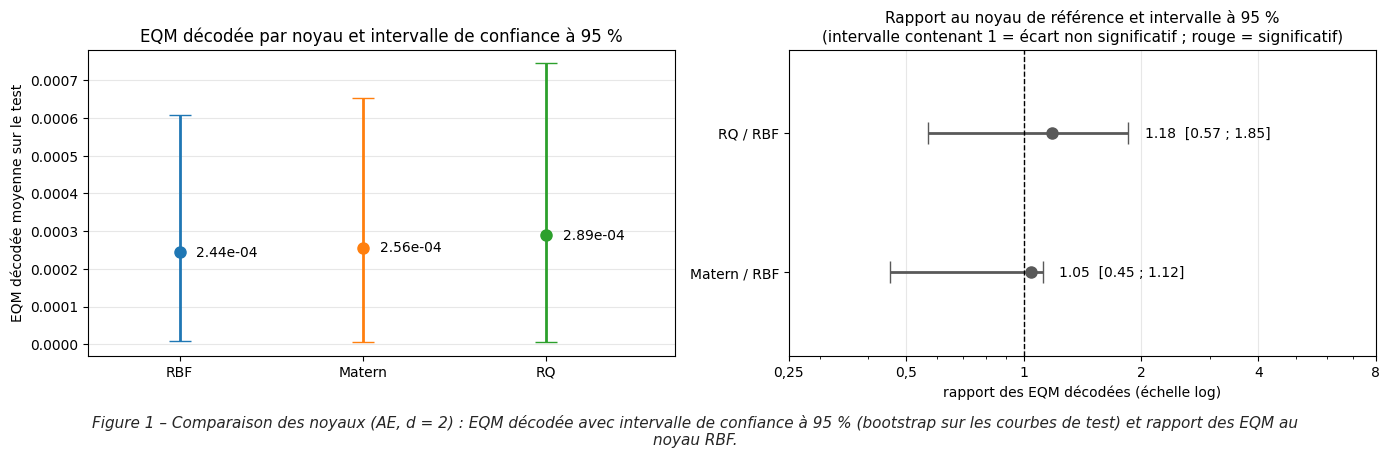

In [13]:
from src.gpr_model import paired_comparison
from src.visualization import plot_kernel_comparison

sig = []
for k in ['Matern', 'RQ']:
    pc = paired_comparison(gpr_errors[k], gpr_errors['RBF'])
    sig.append({'comparaison': f'{k} / RBF', 'ratio des EQM': pc['ratio'],
                'ratio IC95 bas': pc['ratio_ic95'][0], 'ratio IC95 haut': pc['ratio_ic95'][1],
                'part des courbes où le noyau gagne': pc['part_a_meilleur'],
                'p-valeur (Wilcoxon)': pc['p_wilcoxon']})
display(results_table(sig, index='comparaison'))

# Pourquoi les intervalles sont-ils si larges ? Où se concentre l'erreur ?
v, e = X_test[:, 1], gpr_errors['RBF']
print(f"{e[v <= np.quantile(v, 0.1)].sum() / e.sum():.0%} de l'EQM vient des 10 % de courbes les plus "
      f"étroites, {e[np.argmin(v)] / e.sum():.0%} de la seule courbe sigma2 = {v.min():.3f}")

fig = plot_kernel_comparison(gpr_errors, sig)
add_caption(fig, "Comparaison des noyaux (AE, d = 2) : EQM décodée avec intervalle de confiance "
                 "à 95 % (bootstrap sur les courbes de test) et rapport des EQM au noyau RBF.")
plt.show()

In [14]:
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from src.gpr_model import log_variance_features

# 1) La matrice de covariance K du train est-elle inversible ?
K = gpr_rbf.kernel_.k1(log_variance_features(X_train))     # partie C x RBF, sans le WhiteKernel
vp = np.linalg.eigvalsh(K)                                  # valeurs propres de K
print(f"K : {K.shape}, {np.sum(vp < 1e-10)} valeurs propres sur {len(vp)} sont < 1e-10, "
      f"la plus petite vaut {vp.min():.1e}")

# 2) La GPR RBF réentraînée dans trois autres configurations
k_sans_white = C(1.0) * RBF([1.0, 1.0], length_scale_bounds=(1e-2, 1e2))   # même noyau, sans WhiteKernel
configs = [('sans WhiteKernel, alpha = 1e-10', dict(kernel=k_sans_white, alpha=1e-10)),
           ('sans WhiteKernel, alpha = 0', dict(kernel=k_sans_white, alpha=0.0)),
           ('WhiteKernel, alpha = 1e-1 (trop grand)', dict(kernel_name='RBF', alpha=1e-1))]

q22 = [{'configuration': 'WhiteKernel, alpha = 1e-5 (référence, étape 2)',
        'EQM décodée': gpr_errors['RBF'].mean(),
        'RMSE latente relative': latent_rmse_relative(gpr_rbf, X_test, Z_test),
        'noyau optimisé': str(gpr_rbf.kernel_)}]
for label, kw in configs:
    try:
        g = fit_gpr(X_train, Z_train, n_restarts=0, **kw)
        q22.append({'configuration': label,
                    'EQM décodée': decoded_curve_mse(g, ae2.decoder, X_test, y_test),
                    'RMSE latente relative': latent_rmse_relative(g, X_test, Z_test),
                    'noyau optimisé': str(g.kernel_)})
    except Exception as e:                       # le calcul peut échouer : on note l'erreur
        q22.append({'configuration': label, 'noyau optimisé': f'ÉCHEC : {type(e).__name__}'})
display(results_table(q22, index='configuration'))

K : (1600, 1600), 1070 valeurs propres sur 1600 sont < 1e-10, la plus petite vaut -8.2e-14


,EQM décodée,RMSE latente relative,noyau optimisé
configuration,,,
"WhiteKernel, alpha = 1e-5 (référence, étape 2)",2.443e-04,2.986e-01,"1.58**2 * RBF(length_scale=[0.476, 0.692]) + WhiteKernel(noise_level=1e-10)"
"sans WhiteKernel, alpha = 1e-10",3.541e-04,3.934e-01,"1.01**2 * RBF(length_scale=[0.293, 0.288])"
"sans WhiteKernel, alpha = 0",—,—,ÉCHEC : LinAlgError
"WhiteKernel, alpha = 1e-1 (trop grand)",3.515e-04,6.010e-01,"9.37**2 * RBF(length_scale=[3.29, 2.6]) + WhiteKernel(noise_level=1e-10)"


In [15]:
from sklearn.gaussian_process.kernels import WhiteKernel
noyau_sujet = C(1.0) * RBF(1.0) + WhiteKernel(1e-3)     # noyau d'origine du sujet (sans nos bornes)

gpr_rbf_r3 = fit_gpr(X_train, Z_train, kernel_name='RBF', n_restarts=3)
gpr_brut = fit_gpr(X_train, Z_train, kernel=noyau_sujet, log_variance=False, n_restarts=0)

q5a = []
for label, nr, g in [('(mu, log sigma2), RBF borné', 0, gpr_rbf),
                     ('(mu, log sigma2), RBF borné', 3, gpr_rbf_r3),
                     ('entrée brute, noyau du sujet', 0, gpr_brut)]:
    q5a.append({'entrée et noyau': label, 'n_restarts': nr,
                'log-vraisemblance': g.log_marginal_likelihood_value_,
                'EQM décodée': decoded_curve_mse(g, ae2.decoder, X_test, y_test),
                'temps GPR (s)': g.fit_time_, 'noyau optimisé': str(g.kernel_)})
display(results_table(q5a, index=['entrée et noyau', 'n_restarts']))

# entrée brute contre log sigma2 : l'écart est-il significatif ? (comme à l'étape 3)
pc = paired_comparison(decoded_curve_errors(gpr_brut, ae2.decoder, X_test, y_test), gpr_errors['RBF'])
print(f"entrée brute / log sigma2 : ratio {pc['ratio']:.2f}, IC95 [{pc['ratio_ic95'][0]:.2f} ; "
      f"{pc['ratio_ic95'][1]:.2f}], l'entrée brute gagne sur {pc['part_a_meilleur']:.0%} des courbes, "
      f"p = {pc['p_wilcoxon']:.1e}")

entrée brute / log sigma2 : ratio 0.84, IC95 [0.75 ; 3.60], l'entrée brute gagne sur 43% des courbes, p = 1.4e-06


In [16]:
pca10 = pca_reducers[10]
Z10_train, Z10_test = pca10.transform(y_train), pca10.transform(y_test)

q5b = []
for label, nr, kw in [('entrée brute, noyau du sujet', 0, dict(kernel=noyau_sujet, log_variance=False)),
                      ('entrée brute, noyau du sujet', 3, dict(kernel=noyau_sujet, log_variance=False)),
                      ('(mu, log sigma2), RBF borné', 0, dict(kernel_name='RBF'))]:
    g = fit_gpr(X_train, Z10_train, n_restarts=nr, **kw)
    q5b.append({'entrée et noyau': label, 'n_restarts': nr,
                'log-vraisemblance': g.log_marginal_likelihood_value_,
                'EQM décodée': decoded_curve_mse(g, pca10.decoder, X_test, y_test),
                'RMSE latente relative': latent_rmse_relative(g, X_test, Z10_test),
                'temps GPR (s)': g.fit_time_, 'noyau optimisé': str(g.kernel_)})
display(results_table(q5b, index=['entrée et noyau', 'n_restarts']))

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\gaussian_process\kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


**Justification de `n_restarts`.** L'optimisation de la log-vraisemblance marginale peut s'arrêter sur un maximum local ; chaque redémarrage la relance depuis des hyperparamètres tirés au hasard, ce qui coûte une optimisation complète de plus.

- **Le risque est réel.** Avec l'entrée brute $(\mu, \sigma^2)$ et le noyau d'origine du sujet, sur les codes de la PCA ($d = 10$), l'optimisation sans redémarrage s'arrête sur un optimum dégénéré : longueur caractéristique de $10^{-5}$ et bruit de $0{,}16$, la GPR attribue toute la variation des codes au bruit (log-vraisemblance $-22\,703$, RMSE latente relative de $1{,}00$, EQM décodée de $4{,}3 \cdot 10^{-3}$). Trois redémarrages retrouvent le bon optimum (log-vraisemblance $30\,555$, EQM $1{,}55 \cdot 10^{-4}$), au prix de 206 s.
- **Notre configuration évite ce piège.** En travaillant sur $(\mu, \log \sigma^2)$ avec des longueurs caractéristiques bornées, l'optimisation sans redémarrage atteint directement un optimum encore meilleur (log-vraisemblance $68\,403$, même EQM, 90 s). Sur l'AE $d = 2$, 0 et 3 redémarrages donnent exactement la même log-vraisemblance ($11\,976{,}23$), le même noyau et la même EQM ($2{,}44 \cdot 10^{-4}$), pour un temps 5,7 fois plus long (242 s contre 43 s).

On retient donc **`n_restarts = 0`** : les redémarrages n'apportent rien dans notre configuration et multiplient le temps de calcul. Ils resteraient nécessaires avec l'entrée brute.

**Choix de $\log \sigma^2$ pour l'AE.** Avec l'entrée brute, l'EQM décodée moyenne est plus faible ($2{,}04 \cdot 10^{-4}$), mais l'écart n'est pas significatif (rapport $0{,}84$, IC à 95 % $[0{,}75 ; 3{,}60]$) : il se joue sur quelques courbes étroites. Courbe par courbe, $\log \sigma^2$ fait mieux sur 57 % des courbes ($p = 1{,}4 \cdot 10^{-6}$), et sa log-vraisemblance est deux fois plus élevée ($11\,976$ contre $5\,649$). Nous gardons donc $\log \sigma^2$, plus robuste.

AE d =  2 : EQM décodée = 2.443e-04  (43 s)
AE d =  3 : EQM décodée = 2.326e-04  (56 s)
AE d =  5 : EQM décodée = 2.113e-04  (52 s)
AE d = 10 : EQM décodée = 2.435e-04  (95 s)
AE d = 20 : EQM décodée = 2.050e-04  (142 s)
PCA d =  2 : EQM décodée = 1.058e-03  (46 s)
PCA d =  5 : EQM décodée = 3.747e-04  (69 s)
PCA d = 10 : EQM décodée = 1.552e-04  (86 s)
PCA d = 20 : EQM décodée = 1.695e-04  (192 s)


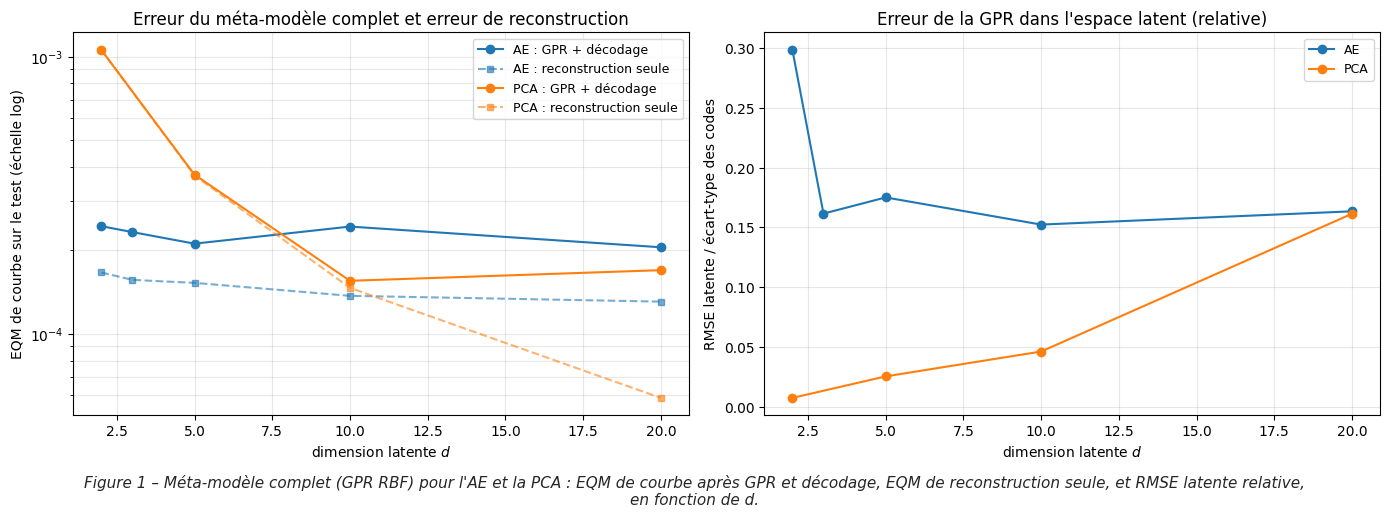

In [17]:
from src.visualization import plot_decoded_vs_d

sweep_cfg = {'AE': (ae_reducers, [2, 3, 5, 10, 20]), 'PCA': (pca_reducers, [2, 5, 10, 20])}
sweep, sweep_errors = [], {}
for red, (reducers_red, ds) in sweep_cfg.items():
    for d in ds:
        reducer = reducers_red[d]
        Ztr, Zte = reducer.transform(y_train), reducer.transform(y_test)
        if (red, d) == ('AE', 2):
            g = gpr_rbf                                     # déjà entraîné à l'étape 2
        else:
            g = fit_gpr(X_train, Ztr, kernel_name='RBF', n_restarts=0)
        sweep_errors[(red, d)] = decoded_curve_errors(g, reducer.decoder, X_test, y_test)
        sweep.append({'réducteur': red, 'd': d,
                      'RMSE latente': latent_rmse(g, X_test, Zte),
                      'RMSE latente relative': latent_rmse_relative(g, X_test, Zte),
                      'EQM reconstruction': reconstruction_mse(reducer, y_test),
                      'EQM décodée': sweep_errors[(red, d)].mean(),
                      'temps GPR (s)': g.fit_time_})
        print(f"{red} d = {d:2d} : EQM décodée = {sweep[-1]['EQM décodée']:.3e}  ({g.fit_time_:.0f} s)")
display(results_table(sweep, index=['réducteur', 'd']))

results = {}
for red in sweep_cfg:
    rows = [r for r in sweep if r['réducteur'] == red]
    results[red] = {col: [r[col] for r in rows]
                    for col in ['d', 'EQM décodée', 'EQM reconstruction', 'RMSE latente relative']}
fig = plot_decoded_vs_d(results)
add_caption(fig, "Méta-modèle complet (GPR RBF) pour l'AE et la PCA : EQM de courbe après GPR et "
                 "décodage, EQM de reconstruction seule, et RMSE latente relative, en fonction de d.")
plt.show()

,ratio des EQM,ratio IC95 bas,ratio IC95 haut,part des courbes où le modèle gagne,p-valeur (Wilcoxon)
comparaison,,,,,
AE d=3 / AE d=2,0.95,0.80,1.06,52%,2.8e-03
AE d=5 / AE d=2,0.86,0.64,0.96,64%,1.9e-15
AE d=10 / AE d=2,1.00,0.39,1.09,64%,2.5e-14
AE d=20 / AE d=2,0.84,0.32,0.95,86%,2.6e-52
PCA d=2 / PCA d=10,6.82,3.65,51.69,0%,2.7e-67
PCA d=5 / PCA d=10,2.42,1.78,10.39,0%,2.7e-67
PCA d=20 / PCA d=10,1.09,0.02,1.46,100%,5.4e-66
AE d=2 / PCA d=10,1.57,0.56,2.13,71%,2.2e-35


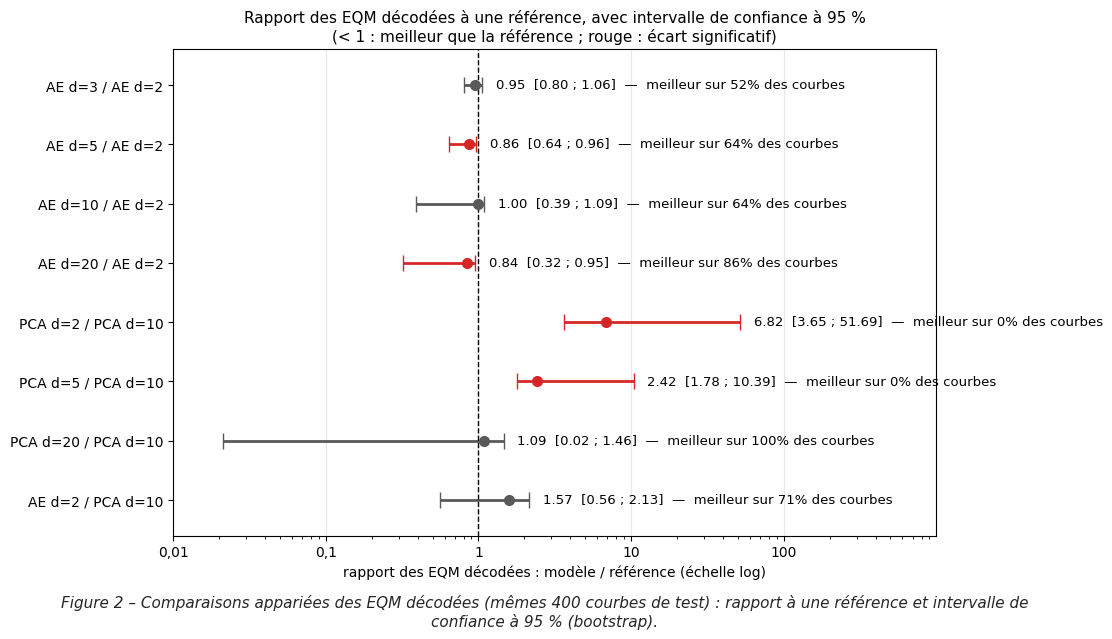

In [19]:
from src.visualization import plot_ratio_ci

paires = ([(('AE', d), ('AE', 2)) for d in [3, 5, 10, 20]]
          + [(('PCA', d), ('PCA', 10)) for d in [2, 5, 20]]
          + [(('AE', 2), ('PCA', 10))])
comparisons = []
for (ra, da), (rb, db) in paires:
    pc = paired_comparison(sweep_errors[(ra, da)], sweep_errors[(rb, db)])
    comparisons.append({'comparaison': f'{ra} d={da} / {rb} d={db}', 'ratio des EQM': pc['ratio'],
                        'ratio IC95 bas': pc['ratio_ic95'][0], 'ratio IC95 haut': pc['ratio_ic95'][1],
                        'part des courbes où le modèle gagne': pc['part_a_meilleur'],
                        'p-valeur (Wilcoxon)': pc['p_wilcoxon']})
display(results_table(comparisons, index='comparaison'))

fig = plot_ratio_ci(comparisons)
add_caption(fig, "Comparaisons appariées des EQM décodées (mêmes 400 courbes de test) : rapport à "
                 "une référence et intervalle de confiance à 95 % (bootstrap).")
plt.show()

**Q2.1.** Quel noyau donne les meilleures prédictions latentes ? L'écart entre noyaux est-il significatif ?

**Q2.2.** Quel est le rôle du `WhiteKernel` et de `alpha` ? Que se passe-t-il si on les supprime ? (Testez sur un cas.)

**Q2.3.** Comment l'erreur décodée dépend-elle de la dimension latente $d$ ? Y a-t-il un « sweet spot » ?

**Réponse Q2.1 :**

**Meilleur noyau.** Le noyau **RBF** donne les meilleures prédictions latentes : RMSE latente de $1{,}98$, contre $2{,}46$ pour RQ et $3{,}11$ pour Matern. Il donne aussi la plus faible EQM de courbe après décodage : $2{,}44 \cdot 10^{-4}$, contre $2{,}56 \cdot 10^{-4}$ pour Matern et $2{,}89 \cdot 10^{-4}$ pour RQ.

**L'écart n'est pas significatif.** Comparés courbe par courbe sur les 400 courbes de test, Matern et RQ ont des EQM décodées $1{,}05$ et $1{,}18$ fois plus élevées que RBF, mais les intervalles de confiance à 95 % de ces rapports, obtenus par bootstrap, contiennent 1 ($[0{,}45 ; 1{,}12]$ et $[0{,}57 ; 1{,}85]$). Chaque noyau fait mieux que RBF sur environ une courbe sur deux (53 % et 50 %), et le test de Wilcoxon ne détecte aucune différence ($p = 0{,}75$ et $0{,}88$).

Ces intervalles sont larges parce que l'erreur se concentre sur très peu de courbes : les 10 % de courbes les plus étroites portent la quasi-totalité de l'EQM, et la seule courbe $\sigma^2 = 0{,}029$ (plus étroite que toutes celles du train, donc extrapolée) en représente 54 %. **Le choix du noyau compte donc peu** ; **on retient le RBF, le plus précis**.

**Réponse Q2.2 :** 

**Rôle.** Pour prédire, la GPR doit inverser la matrice de covariance $K$ des 1600 points du train. `alpha` et `WhiteKernel` ajoutent tous deux une valeur sur la diagonale de $K$, ce qui la rend inversible :
- **`alpha`** est une valeur **fixée** ($10^{-5}$) : elle assure la stabilité numérique et joue le rôle d'une régularisation ;
- **`WhiteKernel`** est un niveau de bruit **appris** par maximisation de la vraisemblance. Ici, il converge vers sa borne minimale ($10^{-10}$)

**Sans eux (testé sur l'AE $d = 2$, noyau RBF).** Sans `WhiteKernel` et avec `alpha = 0`, l'ajustement **échoue** (`LinAlgError` : la matrice n'est pas définie positive). Avec seulement `alpha = 10^{-10}`, il fonctionne mais l'EQM décodée passe de $2{,}44 \cdot 10^{-4}$ à $3{,}54 \cdot 10^{-4}$ (+45 %) : les longueurs caractéristiques rétrécissent ($0{,}29$ au lieu de $0{,}48$ et $0{,}69$), et la GPR colle trop aux points du train au détriment des prédictions entre eux. À l'inverse, un `alpha` trop grand ($10^{-1}$) lisse trop (longueurs de $3{,}3$ et $2{,}6$) et donne une EQM de $3{,}52 \cdot 10^{-4}$ (+44 %). La valeur ajoutée sur la diagonale ne doit donc être ni nulle, ni trop petite, ni trop grande.


**Réponse Q2.3 :**

**PCA : un sweet spot net à $d = 10$**. De $d = 2$ à $d = 10$, l'EQM décodée suit l'EQM de reconstruction ($1{,}06 \cdot 10^{-3}$, $3{,}75 \cdot 10^{-4}$, $1{,}55 \cdot 10^{-4}$) : la GPR prédit les codes presque parfaitement (RMSE latente relative de $0{,}007$ à $0{,}046$) et l'erreur vient de la reconstruction. Au-delà, la tendance s'inverse : à $d = 20$, la reconstruction continue de s'améliorer ($5{,}9 \cdot 10^{-5}$) mais l'EQM décodée remonte ($1{,}70 \cdot 10^{-4}$), car la RMSE latente relative est multipliée par 3,5 ($0{,}16$) : les composantes d'ordre élevé oscillent et sont difficiles à prédire, et la GPR représente alors les deux tiers de l'erreur. L'EQM décodée résulte donc d'un compromis entre erreur de reconstruction (qui diminue avec $d$) et erreur de régression (qui augmente avec $d$). Courbe par courbe, $d = 20$ reste meilleur que $d = 10$ sur la quasi-totalité des courbes ; il ne perd que sur la courbe extrapolée ($\sigma^2 = 0{,}029$), qui domine la moyenne.

**AE : pas de sweet spot marqué.** L'EQM décodée varie peu avec $d$ ($2{,}05$ à $2{,}44 \cdot 10^{-4}$), sans tendance régulière. Les comparaisons appariées montrent que $d = 5$ et $d = 20$ font significativement mieux que $d = 2$ (rapports $0{,}86$ et $0{,}84$, intervalles $[0{,}64 ; 0{,}96]$ et $[0{,}32 ; 0{,}95]$), mais le gain reste modeste (14 à 16 %). La RMSE latente absolue baisse fortement avec $d$ (de $1{,}98$ à $0{,}36$) sans que l'erreur décodée suive : elle dépend de l'échelle des codes, différente pour chaque $d$, et n'est pas comparable d'une dimension à l'autre. La RMSE relative, elle, chute de $0{,}30$ à $d = 2$ à environ $0{,}16$ dès $d = 3$, puis stagne.

**AE ou PCA ?** La PCA à $d = 10$ a une EQM moyenne plus faible que l'AE à $d = 2$ (rapport $1{,}57$), mais l'écart n'est pas significatif (intervalle $[0{,}56 ; 2{,}13]$), et l'AE fait mieux sur 71 % des courbes ($p = 2{,}2 \cdot 10^{-35}$) : la moyenne est dominée par quelques courbes étroites, sur lesquelles la PCA fait mieux.

## Partie 3 — Probabilité de dépassement d'un seuil

On assemble le méta-modèle complet et on estime, par Monte Carlo, la probabilité que la courbe aléatoire dépasse le seuil $\tau = 0.1$ en chaque position $x$ :

$$\hat p(x) = \frac{1}{L}\sum_{l=1}^{L} \mathbf{1}\big\{\hat y^{(l)}(x) \geq \tau\big\}, \qquad \hat{\mathbf y}^{(l)} = f_\theta\big(\psi(\mu^{(l)}, (\sigma^2)^{(l)})\big),$$

où $(\mu^{(l)}, (\sigma^2)^{(l)})$ sont $L = 20\,000$ tirages de la loi d'entrée. Complétez `mc_exceedance` dans `src/exceedance.py`.

### Référence exacte (fournie)

Pour cette loi d'entrée (moyenne uniforme, variance gamma), la probabilité exacte s'obtient par intégration numérique à une dimension : conditionnellement à $\sigma^2 = v$, l'événement $\{\phi(x;\mu,\sigma^2)\geq\tau\}$ équivaut à $\mu \in [x-c(v),\, x+c(v)]$ avec $c(v)=\sqrt{2v\ln\frac{1}{\tau\sqrt{2\pi v}}}$ (nécessite $v < v_\tau = \frac{1}{2\pi\tau^2}$), d'où

$$E(x) = \int_0^{v_\tau} \frac{\big|[x-c(v),\,x+c(v)]\big|}{8}\; \gamma(v; 2, 2)\, dv .$$

La cellule ci-dessous calcule cette référence : **exécutez-la, puis répondez aux questions après avoir implémenté la partie Monte Carlo.**

v_tau = 15.9155 ; E(x) in [0.0000, 0.5300]


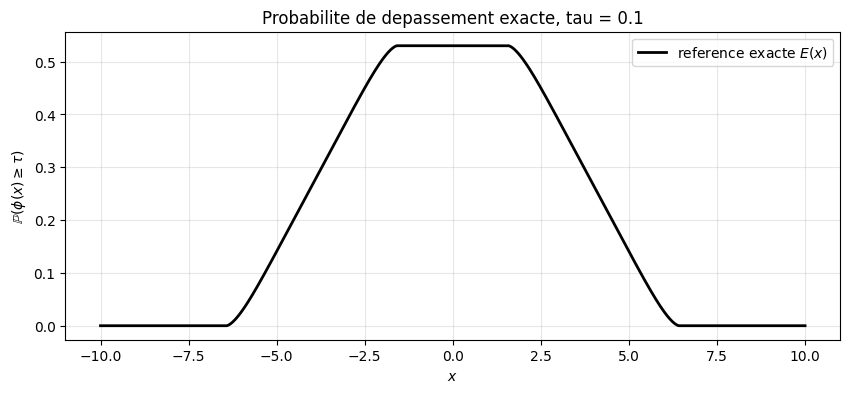

In [20]:
# --- reference exacte (FOURNIE, ne pas modifier) ---
from scipy.integrate import quad
from scipy.stats import gamma

tau = 0.1
v_tau = 1.0 / (2.0 * np.pi * tau**2)

def exact_exceedance(x):
    def integrand(v):
        c = np.sqrt(2.0 * v * np.log(1.0 / (tau * np.sqrt(2.0 * np.pi * v))))
        lo, hi = max(x - c, mu_min), min(x + c, mu_max)
        return max(hi - lo, 0.0) / (mu_max - mu_min) * gamma.pdf(v, a=k_shape, scale=theta_scale)
    return quad(integrand, 0.0, v_tau, epsabs=1e-12)[0]

p_exact = np.array([exact_exceedance(x) for x in x_grid])
print(f"v_tau = {v_tau:.4f} ; E(x) in [{p_exact.min():.4f}, {p_exact.max():.4f}]")

plt.figure(figsize=(10, 4))
plt.plot(x_grid, p_exact, 'k-', lw=2, label=r'reference exacte $E(x)$')
plt.xlabel(r'$x$'); plt.ylabel(r'$\mathbb{P}(\phi(x)\geq\tau)$')
plt.title(f'Probabilite de depassement exacte, tau = {tau}')
plt.legend(); plt.grid(alpha=0.3); plt.show()

Consignes :
1. Complétez `mc_exceedance(gpr, decoder, n_samples, tau)` dans `src/exceedance.py` : tirage des paramètres selon la loi d'entrée, prédiction GPR, décodage, moyenne des indicateurs.
2. Tracez sur un même graphe : la référence exacte, $\hat p(x)$ pour votre meilleur méta-modèle de la Partie 2, et — à titre de contrôle — la probabilité empirique obtenue par Monte Carlo sur le **vrai simulateur** (courbes exactes, mêmes tirages).
3. Quantifiez : erreur en aire $\int |\hat p - E|\,dx$, erreur max, corrélation entre les profils.

```python
# --- snippet d'aide ---
mu_l    = np.random.uniform(mu_min, mu_max, L)
var_l   = np.random.gamma(k_shape, theta_scale, L)
X_mc    = np.column_stack([mu_l, var_l])
Z_mc    = gpr.predict(X_mc)                # prediction latente
curves  = decoder.predict(Z_mc)            # ou decoder(Z_mc) selon votre librairie
p_hat   = (curves >= tau).mean(axis=0)
```

In [21]:
from src.exceedance import (mc_exceedance, mc_exceedance_true_simulator,
                            area_error, exceedance_metrics)

# 1) Le contrôle « vrai simulateur » doit retrouver la référence exacte, au bruit Monte-Carlo près
rng = np.random.default_rng(0)
X_check = np.column_stack([rng.uniform(mu_min, mu_max, 20000),
                           rng.gamma(k_shape, theta_scale, 20000)])
p_check = mc_exceedance_true_simulator(x_grid, tau, X_check, gaussian_pdf)
print('Vrai simulateur, L = 20000 :', exceedance_metrics(p_check, p_exact, x_grid))

# 2) mc_exceedance tourne-t-il avec le méta-modèle ? (petit L, juste pour vérifier)
p_test, X_mc_test = mc_exceedance(gpr_rbf, ae2.decoder, tau, 1000, mu_min, mu_max,
                                  k_shape, theta_scale)
print('Méta-modèle, L = 1000 : p_hat', p_test.shape, '| X_mc', X_mc_test.shape,
      f'| p_hat entre {p_test.min():.3f} et {p_test.max():.3f}')

Vrai simulateur, L = 20000 : {'erreur L1 (aire)': 0.046926082815427254, 'erreur max': 0.009209640403637809, "x de l'erreur max": 1.0638297872340416, 'corrélation': 0.9998660727939818}
Méta-modèle, L = 1000 : p_hat (800,) | X_mc (1000, 2) | p_hat entre 0.000 et 0.540


,erreur L1 (aire),erreur max,x de l'erreur max,corrélation
comparaison,,,,
méta-modèle / référence exacte,0.023244,0.006817,-1.614518,0.999967
vrai simulateur / référence exacte (bruit MC seul),0.020250,0.005790,1.163955,0.999974
méta-modèle / vrai simulateur (erreur du méta-modèle),0.016616,0.004550,1.389237,0.999988


Part des x où l'écart à E dépasse la bande du bruit MC : méta-modèle 2%, vrai simulateur 0%


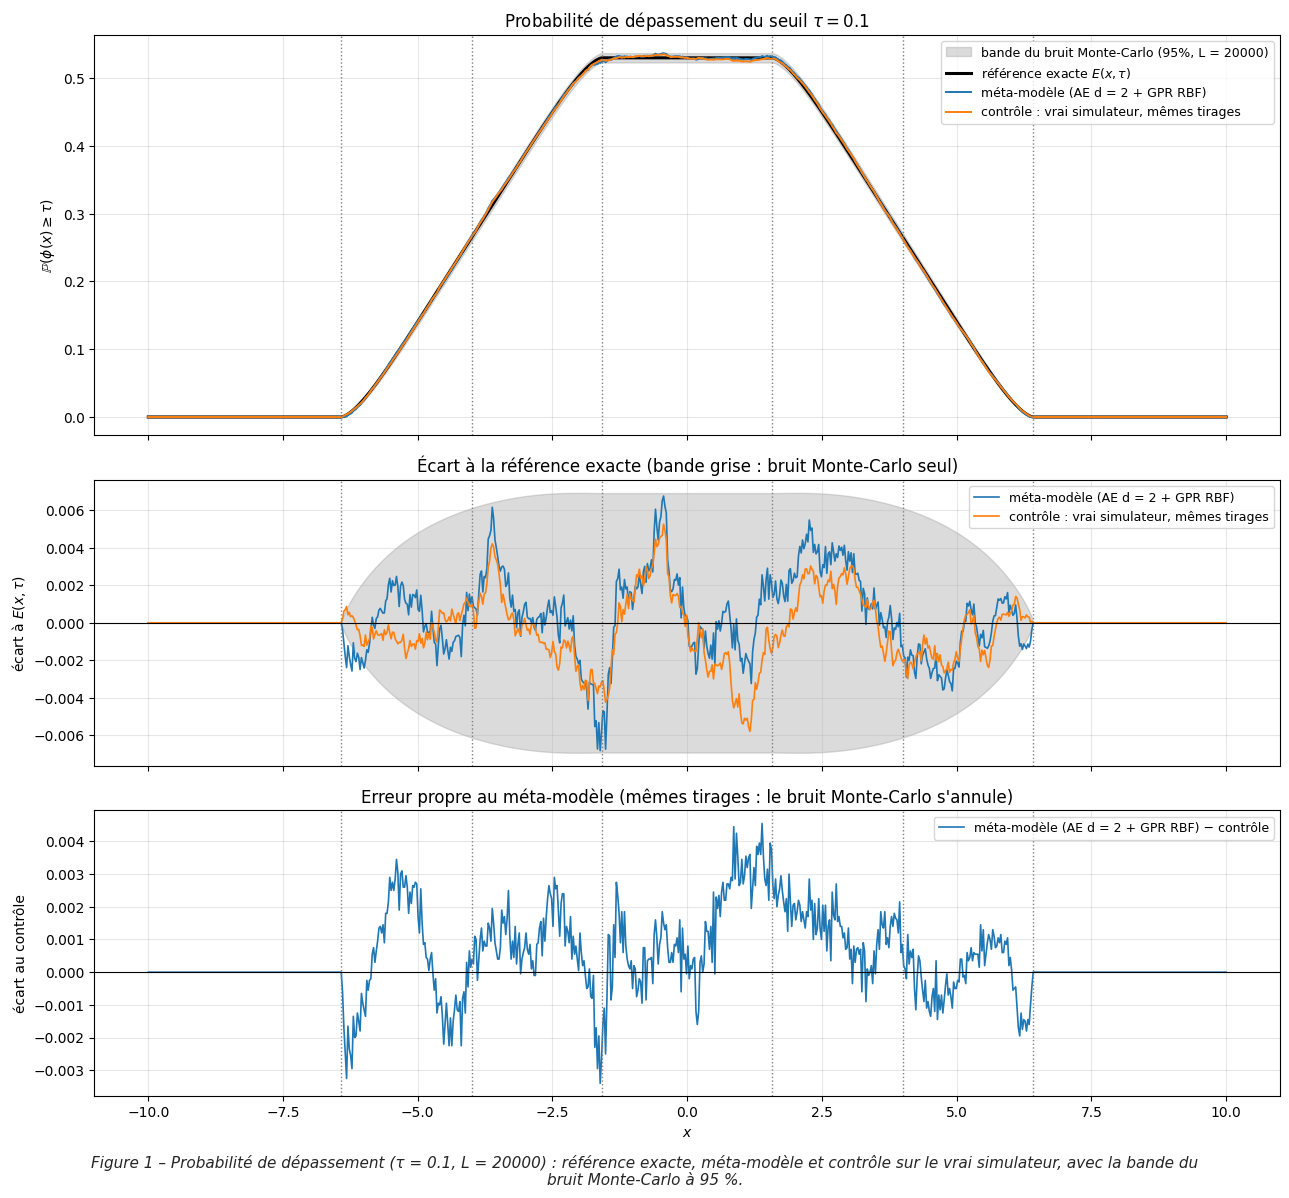

In [22]:
from src.visualization import plot_exceedance

L = 20000
p_hat, X_mc = mc_exceedance(gpr_rbf, ae2.decoder, tau, L, mu_min, mu_max,
                            k_shape, theta_scale, seed=42)
p_true = mc_exceedance_true_simulator(x_grid, tau, X_mc, gaussian_pdf)     # mêmes tirages X_mc

q31 = [{'comparaison': 'méta-modèle / référence exacte', **exceedance_metrics(p_hat, p_exact, x_grid)},
       {'comparaison': 'vrai simulateur / référence exacte (bruit MC seul)', **exceedance_metrics(p_true, p_exact, x_grid)},
       {'comparaison': 'méta-modèle / vrai simulateur (erreur du méta-modèle)', **exceedance_metrics(p_hat, p_true, x_grid)}]
display(results_table(q31, index='comparaison'))

half = 1.96 * np.sqrt(p_exact * (1 - p_exact) / L)
print(f"Part des x où l'écart à E dépasse la bande du bruit MC : "
      f"méta-modèle {np.mean(np.abs(p_hat - p_exact) > half):.0%}, "
      f"vrai simulateur {np.mean(np.abs(p_true - p_exact) > half):.0%}")

fig = plot_exceedance(x_grid, p_exact,
                      {'méta-modèle (AE d = 2 + GPR RBF)': p_hat,
                       'contrôle : vrai simulateur, mêmes tirages': p_true},
                      L, tau, zones=[-6.42, -4, -1.58, 1.58, 4, 6.42],
                      control='contrôle : vrai simulateur, mêmes tirages')
add_caption(fig, f"Probabilité de dépassement (τ = {tau}, L = {L}) : référence exacte, méta-modèle "
                 "et contrôle sur le vrai simulateur, avec la bande du bruit Monte-Carlo à 95 %.")
plt.show()

,bruit MC : moyenne,bruit MC : IC95 bas,bruit MC : IC95 haut,erreur méta-modèle : moyenne,erreur méta-modèle : IC95 bas,erreur méta-modèle : IC95 haut,erreur totale : moyenne,erreur totale : IC95 bas,erreur totale : IC95 haut
L,,,,,,,,,
1000,0.1341,0.0841,0.2298,0.0207,0.0187,0.0237,0.1353,0.0834,0.2350
10000,0.0440,0.0237,0.0848,0.0146,0.0134,0.0159,0.0468,0.0260,0.0903
20000,0.0323,0.0180,0.0500,0.0147,0.0134,0.0158,0.0355,0.0230,0.0559


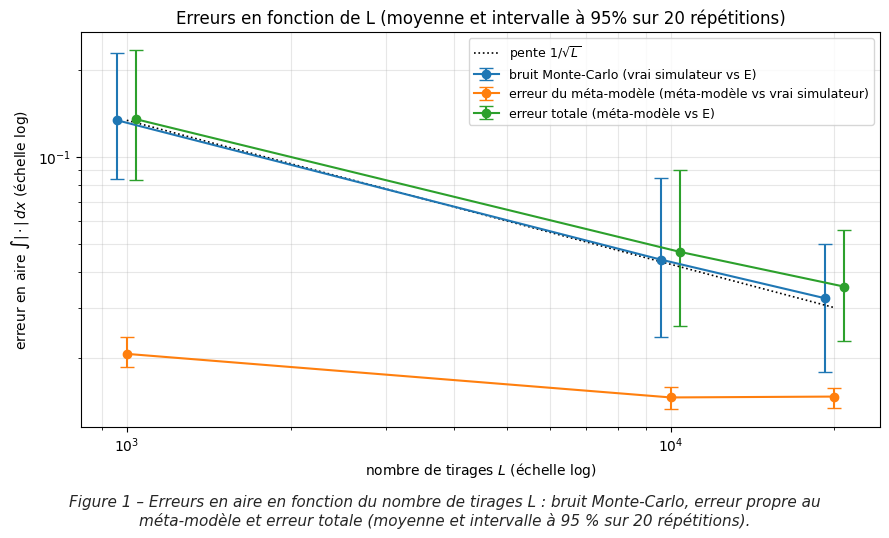

In [25]:
import pandas as pd
from src.exceedance import mc_error_study
from src.visualization import plot_error_vs_L

L_values = [1000, 10000, 20000]
records_L = mc_error_study(gpr_rbf, ae2.decoder, x_grid, p_exact, tau, L_values, n_repeats=20,
                           mu_min=mu_min, mu_max=mu_max, k_shape=k_shape,
                           theta_scale=theta_scale, gaussian_pdf=gaussian_pdf)


# Tableau : moyenne et intervalle à 95 % sur les 20 répétitions
cols = ['bruit MC', 'erreur méta-modèle', 'erreur totale']
df_L = pd.DataFrame(records_L)
resume = df_L.groupby('L')[cols].agg(['mean', lambda s: s.quantile(0.025),
                                       lambda s: s.quantile(0.975)])
resume.columns = [f'{c} : {s}' for c in cols for s in ['moyenne', 'IC95 bas', 'IC95 haut']]
display(resume.round(4))

fig = plot_error_vs_L(records_L)
add_caption(fig, "Erreurs en aire en fonction du nombre de tirages L : bruit Monte-Carlo, erreur "
                 "propre au méta-modèle et erreur totale (moyenne et intervalle à 95 % sur 20 répétitions).")
plt.show()

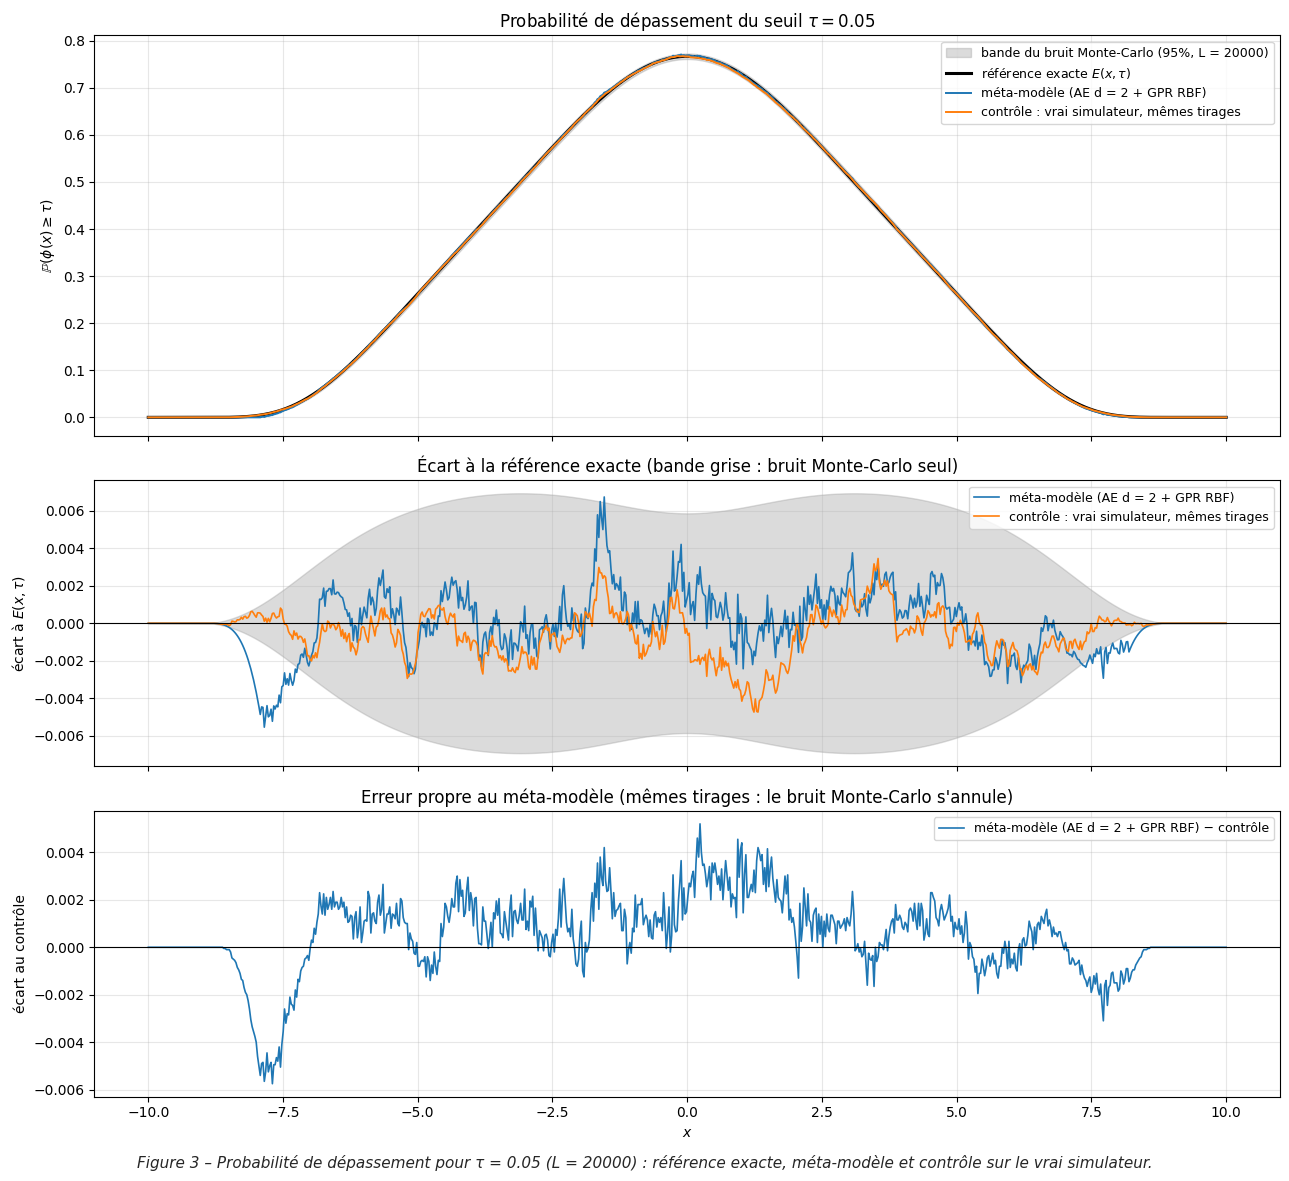

d:\Master\2_année\Semestre 1\MTH2329\Projet-MTH2329-A2026\src\exceedance.py:55: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  return quad(integrand, 0.0, v_tau,


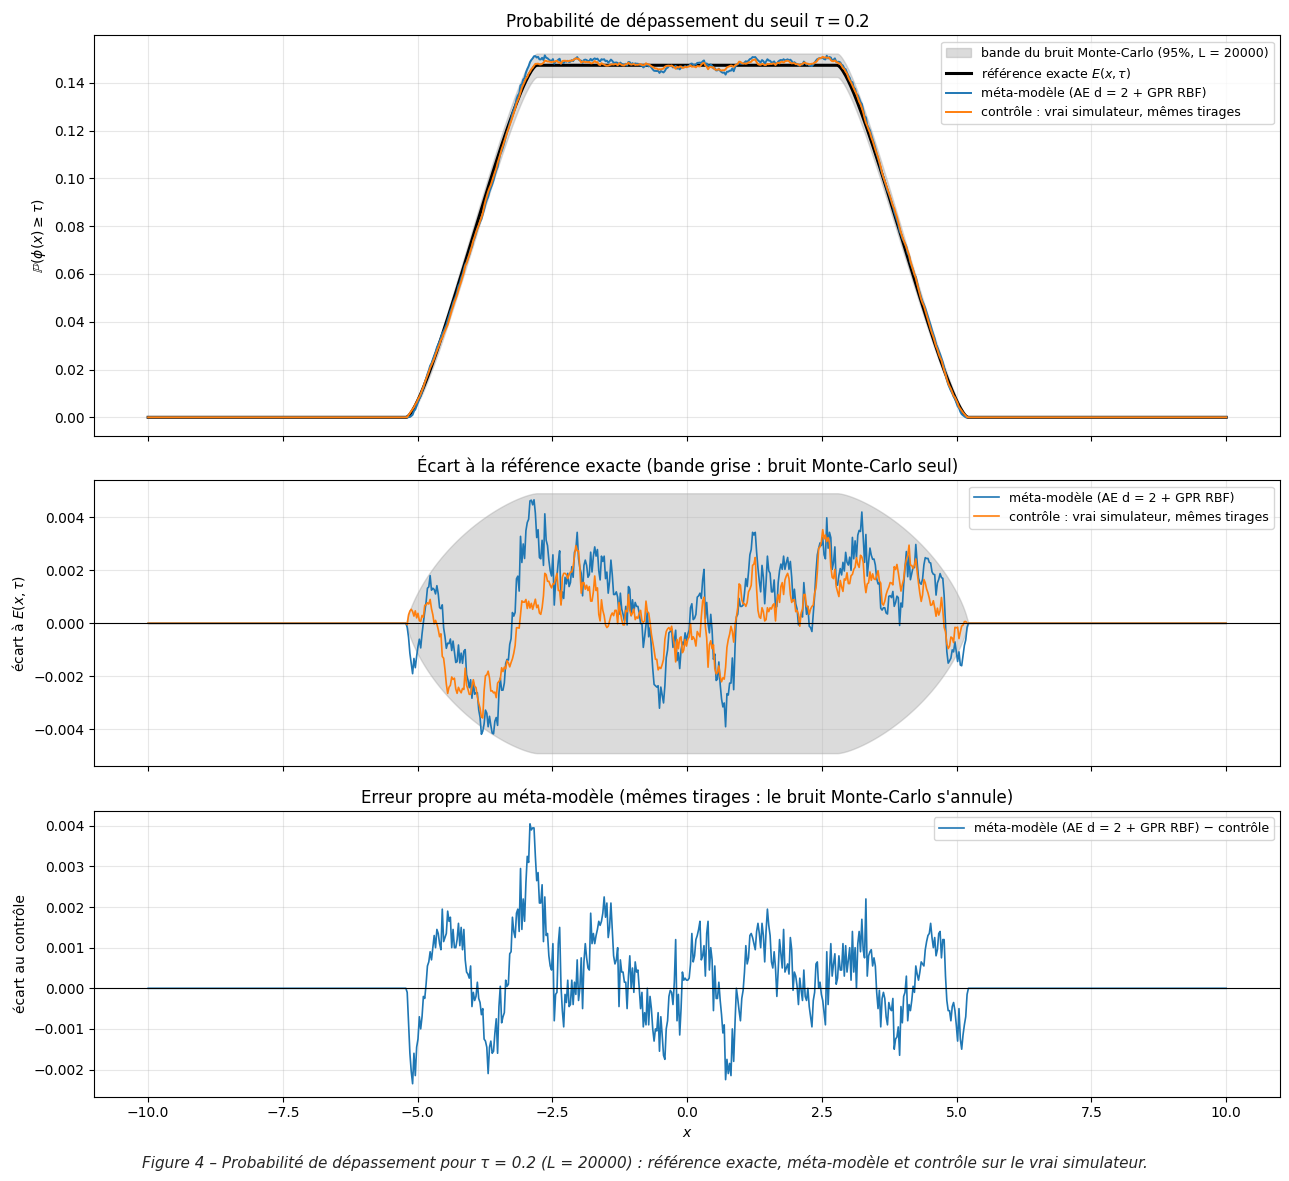

,aire sous E,bruit MC (moyenne),erreur méta-modèle (moyenne),erreur méta-modèle : IC95 bas,erreur méta-modèle : IC95 haut,erreur méta-modèle relative (%)
tau,,,,,,
0.05,6.1942,0.0377,0.0233,0.0216,0.0246,0.3754
0.10,4.2403,0.0323,0.0147,0.0134,0.0158,0.3474
0.20,1.1789,0.0194,0.0095,0.0090,0.0100,0.8083


In [31]:
from src.exceedance import make_exact_exceedance

L = 20000
res33 = []
for tau_b in [0.05, 0.1, 0.2]:
    E_b = make_exact_exceedance(tau_b, mu_min, mu_max, k_shape, theta_scale)
    p_ex_b = np.array([E_b(xx) for xx in x_grid])                # référence exacte pour ce seuil
    rec = pd.DataFrame(mc_error_study(gpr_rbf, ae2.decoder, x_grid, p_ex_b, tau_b, [L], n_repeats=20,
                                      mu_min=mu_min, mu_max=mu_max, k_shape=k_shape,
                                      theta_scale=theta_scale, gaussian_pdf=gaussian_pdf))
    aire_E = area_error(p_ex_b, np.zeros_like(p_ex_b), x_grid)[0]   # aire sous E(x, tau)
    me = rec['erreur méta-modèle']
    res33.append({'tau': tau_b, 'aire sous E': aire_E,
                  'bruit MC (moyenne)': rec['bruit MC'].mean(),
                  'erreur méta-modèle (moyenne)': me.mean(),
                  'erreur méta-modèle : IC95 bas': me.quantile(0.025),
                  'erreur méta-modèle : IC95 haut': me.quantile(0.975),
                  'erreur méta-modèle relative (%)': 100 * me.mean() / aire_E})
    if tau_b != 0.1:                                              # profils pour les deux nouveaux seuils
        p_hat_b, X_mc_b = mc_exceedance(gpr_rbf, ae2.decoder, tau_b, L, mu_min, mu_max,
                                        k_shape, theta_scale, seed=42)
        p_true_b = mc_exceedance_true_simulator(x_grid, tau_b, X_mc_b, gaussian_pdf)
        fig = plot_exceedance(x_grid, p_ex_b,
                              {'méta-modèle (AE d = 2 + GPR RBF)': p_hat_b,
                               'contrôle : vrai simulateur, mêmes tirages': p_true_b},
                              L, tau_b, control='contrôle : vrai simulateur, mêmes tirages')
        add_caption(fig, f"Probabilité de dépassement pour τ = {tau_b} (L = {L}) : référence exacte, "
                         "méta-modèle et contrôle sur le vrai simulateur.")
        plt.show()
display(pd.DataFrame(res33).set_index('tau').round(4))

**Q3.1.** Le profil $\hat p(x)$ du méta-modèle est-il conforme à la référence exacte ? Repérez les zones de plus grande erreur et expliquez-les (pensez aux bords du domaine des paramètres et à la reconstruction).

**Q3.2.** Faites varier $L \in \{10^3, 10^4, 2\cdot 10^4\}$ : comment évolue l'erreur ? Séparez, en vous aidant du contrôle « vrai simulateur », la part d'erreur due au bruit de Monte Carlo de celle due au méta-modèle.

**Q3.3.** *(Bonus)* Reprenez la question avec $\tau \in \{0.05, 0.2\}$. Le méta-modèle reste-t-il précis pour les seuils extrêmes ?

**Réponse Q3.1 :** 

Le profil $\hat p(x)$ est conforme à la référence exacte (Figure n) : corrélation de $0{,}99997$, erreur en aire de $0{,}023$, erreur maximale de $0{,}0068$, et il ne sort de la bande du bruit Monte-Carlo (95 %) que sur 2 % des points. Le contrôle sur le vrai simulateur (mêmes tirages) donne déjà $0{,}020$ en aire : l'essentiel de l'écart est du bruit Monte-Carlo, et l'erreur propre au méta-modèle reste faible ($0{,}017$ en aire, $0{,}0046$ au maximum). Les queues ($|x| > 6{,}42$) sont exactes ; l'erreur se concentre vers $x \approx \pm 1{,}6$ et $\pm 6{,}3$ (maximum en $x = -1{,}61$), là où les courbes qui décident du dépassement ont un $\mu$ proche du bord du domaine ($\pm 4$), où la GPR dispose de moins de voisins. Le méta-modèle est précis parce que seule compte la position de la courbe par rapport à $\tau$ : ses erreurs sur la hauteur des pics étroits ne changent pas le résultat.

**Réponse Q3.2 :**

Sur 20 répétitions par valeur de $L$ (Figure n), le bruit Monte-Carlo (vrai simulateur comparé à $E$) décroît comme $1/\sqrt{L}$ : son erreur en aire passe de $0{,}134$ ($L = 10^3$) à $0{,}044$ ($10^4$) puis $0{,}032$ ($2 \cdot 10^4$), soit des facteurs $3{,}0$ et $1{,}4$ proches des valeurs théoriques $\sqrt{10} \approx 3{,}2$ et $\sqrt{2} \approx 1{,}4$. L'erreur propre au méta-modèle (comparé au vrai simulateur à tirages identiques) se stabilise au contraire vers $0{,}015$ dès $L = 10^4$ (intervalle à 95 % : $[0{,}013 ; 0{,}016]$) : c'est un biais, que l'augmentation de $L$ ne réduit pas. À $L = 2 \cdot 10^4$, le bruit Monte-Carlo reste environ deux fois plus grand que ce biais et domine l'erreur totale ($0{,}036$) ; les deux s'égaliseraient vers $L \approx 10^5$, au-delà duquel seule une amélioration du méta-modèle réduirait l'erreur.


**Réponse Q3.3 :**

Le méta-modèle reste précis pour les deux seuils (Figures n et m) : son erreur propre vaut $0{,}023$ pour $\tau = 0{,}05$ et $0{,}0095$ pour $\tau = 0{,}2$, soit moins de 1 % de l'aire sous $E(x, \tau)$, et reste inférieure au bruit Monte-Carlo ($0{,}038$ et $0{,}019$). Rapportée à cette aire, elle double toutefois pour $\tau = 0{,}2$ ($0{,}81$ % contre $0{,}35$ % pour $\tau = 0{,}1$) : seules les courbes étroites ($\sigma^2 < 4$) peuvent dépasser ce seuil, or ce sont celles que l'AE reconstruit le moins bien et les moins représentées dans le train. Pour $\tau = 0{,}05$, l'erreur relative reste faible ($0{,}38$ %) mais se concentre en bord de support (vers $x \approx -8$), où le dépassement dépend de la queue de courbes très larges ($\sigma^2$ jusqu'à 64), quasi absentes du train : le méta-modèle y extrapole. La précision se dégrade donc aux seuils extrêmes, pour deux raisons opposées : les courbes étroites pour un seuil haut, les courbes très larges pour un seuil bas.

## Partie 4 — Synthèse et discussion

Consignes :
1. Construisez un **tableau récapitulatif** : méthode de réduction × dimension $d$ × noyau → EQM reconstruction, RMSE latente, EQM décodée, erreur en aire sur $E(x,\tau)$.
2. Choisissez **un** méta-modèle final et justifiez ce choix.
3. Discutez ce qui changerait si le simulateur était réellement coûteux (quelques minutes par évaluation) : quel gain de temps le méta-modèle apporte-t-il pour produire $L = 20\,000$ courbes ?

In [28]:
gpr_ae5 = fit_gpr(X_train, ae_reducers[5].transform(y_train), kernel_name='RBF', n_restarts=0)
gpr_pca10 = fit_gpr(X_train, pca_reducers[10].transform(y_train), kernel_name='RBF', n_restarts=0)

candidats = {'AE d=2': (gpr_rbf, ae2.decoder),
             'AE d=5': (gpr_ae5, ae_reducers[5].decoder),
             'PCA d=10': (gpr_pca10, pca_reducers[10].decoder)} 

,erreur méta-modèle : moyenne,erreur méta-modèle : IC95 bas,erreur méta-modèle : IC95 haut,erreur totale : moyenne
candidat,,,,
AE d=2,0.0147,0.0134,0.0158,0.0355
AE d=5,0.0124,0.0116,0.0133,0.0345
PCA d=10,0.0367,0.0336,0.0389,0.0483


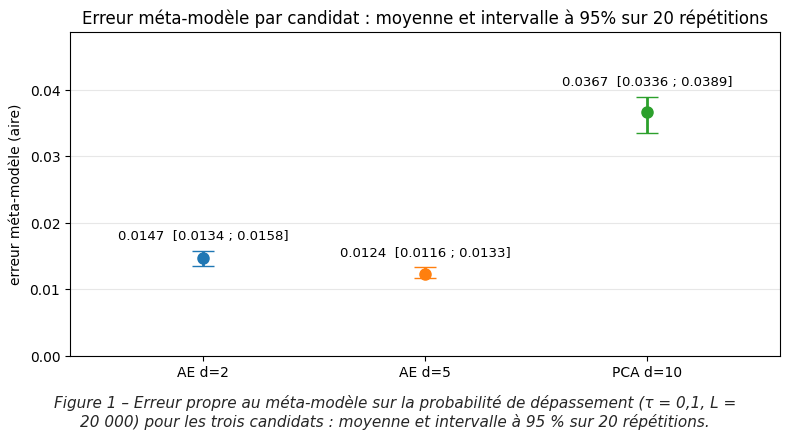

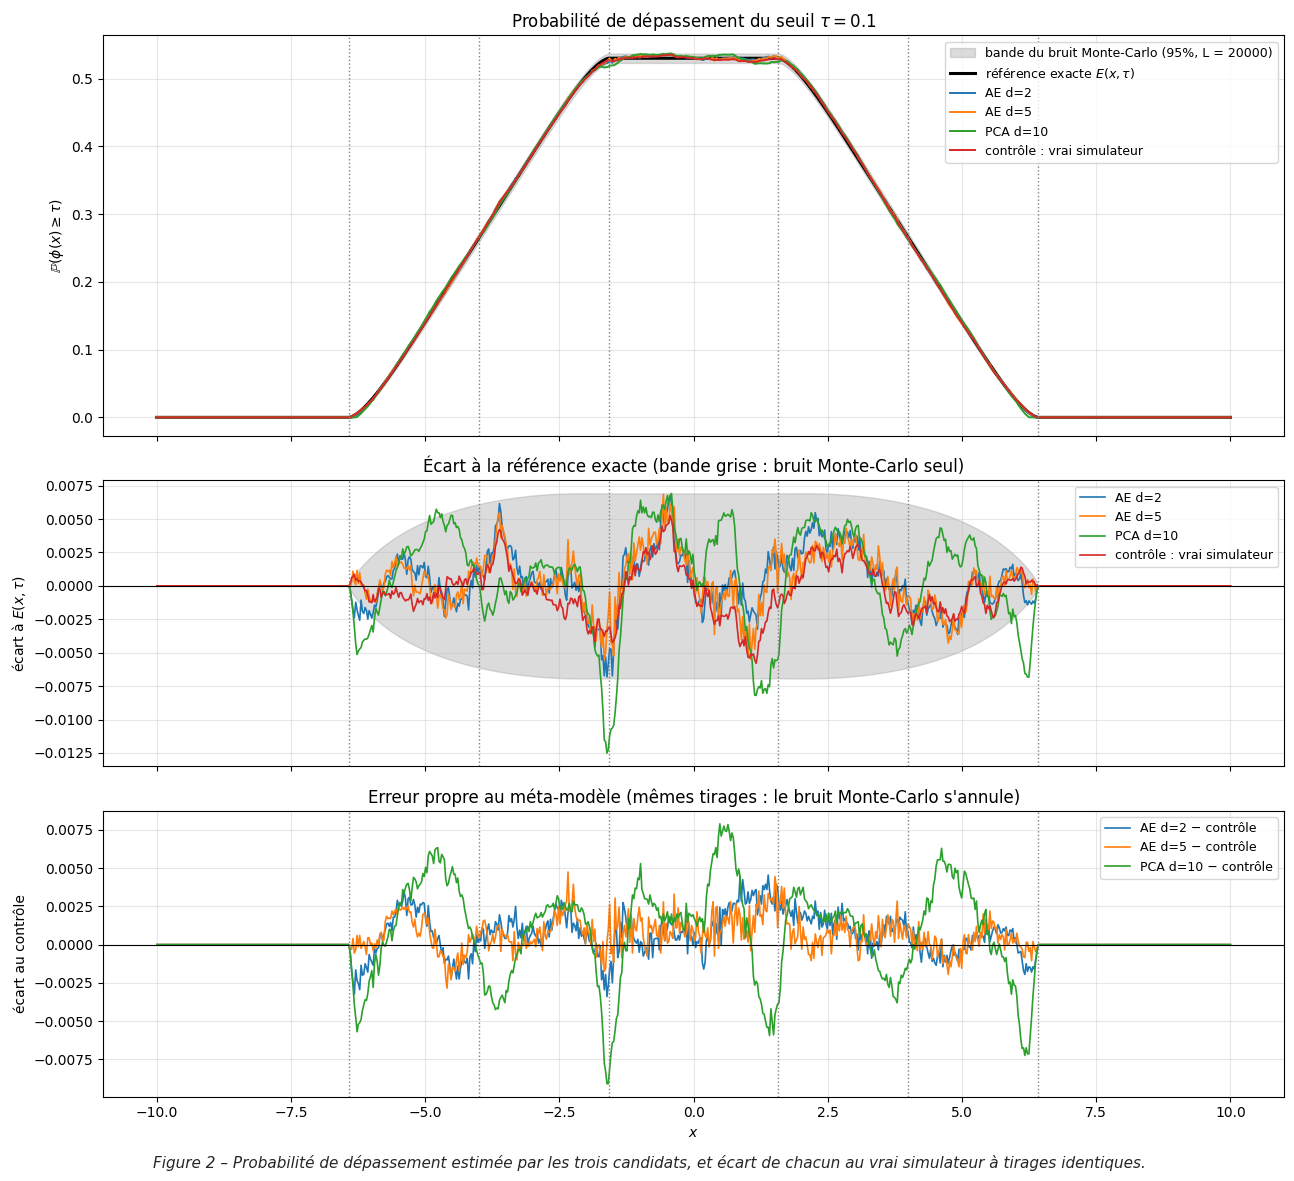

In [29]:
from src.visualization import plot_candidates_ci

L = 20000
etude, resume5, profils = {}, [], {}
for nom, (g, dec) in candidats.items():
    rec = pd.DataFrame(mc_error_study(g, dec, x_grid, p_exact, tau, [L], n_repeats=20,
                                      mu_min=mu_min, mu_max=mu_max, k_shape=k_shape,
                                      theta_scale=theta_scale, gaussian_pdf=gaussian_pdf))
    etude[nom] = rec
    resume5.append({'candidat': nom,
                    'erreur méta-modèle : moyenne': rec['erreur méta-modèle'].mean(),
                    'erreur méta-modèle : IC95 bas': rec['erreur méta-modèle'].quantile(0.025),
                    'erreur méta-modèle : IC95 haut': rec['erreur méta-modèle'].quantile(0.975),
                    'erreur totale : moyenne': rec['erreur totale'].mean()})
    profils[nom], X_mc5 = mc_exceedance(g, dec, tau, L, mu_min, mu_max, k_shape,
                                        theta_scale, seed=42)
display(pd.DataFrame(resume5).set_index('candidat').round(4))

fig = plot_candidates_ci(etude)
add_caption(fig, "Erreur propre au méta-modèle sur la probabilité de dépassement (τ = 0,1, "
                 "L = 20 000) pour les trois candidats : moyenne et intervalle à 95 % sur 20 répétitions.")
plt.show()

# Où chaque candidat se trompe-t-il ? (profils sur les mêmes tirages, graine 42)
p_true5 = mc_exceedance_true_simulator(x_grid, tau, X_mc5, gaussian_pdf)
fig = plot_exceedance(x_grid, p_exact, {**profils, 'contrôle : vrai simulateur': p_true5}, L, tau,
                      zones=[-6.42, -4, -1.58, 1.58, 4, 6.42], control='contrôle : vrai simulateur')
add_caption(fig, "Probabilité de dépassement estimée par les trois candidats, et écart de chacun "
                 "au vrai simulateur à tirages identiques.")
plt.show()

In [30]:
pc = paired_comparison(etude['AE d=5']['erreur méta-modèle'].values,
                       etude['AE d=2']['erreur méta-modèle'].values)
print(f"AE d=5 / AE d=2 : ratio {pc['ratio']:.2f}, IC95 [{pc['ratio_ic95'][0]:.2f} ; "
      f"{pc['ratio_ic95'][1]:.2f}], d=5 meilleur sur {pc['part_a_meilleur']:.0%} des répétitions, "
      f"p = {pc['p_wilcoxon']:.1e}")

AE d=5 / AE d=2 : ratio 0.84, IC95 [0.82 ; 0.85], d=5 meilleur sur 100% des répétitions, p = 1.9e-06


**Comparaison des candidats sur la probabilité de dépassement** ($\tau = 0{,}1$, $L = 20\,000$, 20 répétitions, Figures n et m). L'erreur propre au méta-modèle vaut $0{,}0147$ pour l'AE $d = 2$, $0{,}0124$ pour l'AE $d = 5$ et $0{,}0367$ pour la PCA $d = 10$. Le classement s'inverse par rapport à l'EQM de courbe de la Partie 2 : la PCA, meilleure en EQM moyenne, est 2,5 fois moins précise ici, car les ondulations de ses courbes reconstruites les font passer à tort au-dessus ou au-dessous de $\tau$. Le critère pertinent pour choisir le méta-modèle est donc l'erreur sur la quantité estimée, pas l'EQM de courbe.

In [32]:
# Étape 4.1 — tableau récapitulatif méthode x d x noyau
configs = ([('AE', d, 'RBF') for d in [2, 3, 5, 10, 20]]
           + [('AE', 2, 'Matern'), ('AE', 2, 'RQ')]
           + [('PCA', d, 'RBF') for d in [2, 5, 10, 20]])
gpr_store = {('AE', 2, 'RBF'): gpr_rbf, ('AE', 2, 'Matern'): gpr_models['Matern'],
             ('AE', 2, 'RQ'): gpr_models['RQ'], ('AE', 5, 'RBF'): gpr_ae5,
             ('PCA', 10, 'RBF'): gpr_pca10}                 # GPR déjà entraînées
reducers = {'AE': ae_reducers, 'PCA': pca_reducers}
L = 20000

synthese = []
for red, d, k in configs:
    reducer = reducers[red][d]
    Ztr, Zte = reducer.transform(y_train), reducer.transform(y_test)
    if (red, d, k) not in gpr_store:                         # GPR manquante : on l'entraîne
        gpr_store[(red, d, k)] = fit_gpr(X_train, Ztr, kernel_name=k, n_restarts=0)
    g = gpr_store[(red, d, k)]
    p_hat_c, X_mc_c = mc_exceedance(g, reducer.decoder, tau, L, mu_min, mu_max,
                                    k_shape, theta_scale, seed=42)
    p_true_c = mc_exceedance_true_simulator(x_grid, tau, X_mc_c, gaussian_pdf)
    synthese.append({'méthode': red, 'd': d, 'noyau': k,
                     'EQM reconstruction': reconstruction_mse(reducer, y_test),
                     'RMSE latente': latent_rmse(g, X_test, Zte),
                     'RMSE latente relative': latent_rmse_relative(g, X_test, Zte),
                     'EQM décodée': decoded_curve_mse(g, reducer.decoder, X_test, y_test),
                     'erreur en aire : méta-modèle vs vrai simulateur': area_error(p_hat_c, p_true_c, x_grid)[0],
                     'erreur en aire : totale vs E': area_error(p_hat_c, p_exact, x_grid)[0],
                     'temps GPR (s)': g.fit_time_})
    print(f"{red} d={d:2d} {k:6s} : erreur en aire (méta-modèle) = "
          f"{synthese[-1]['erreur en aire : méta-modèle vs vrai simulateur']:.4f}")

cols_aire = ['erreur en aire : méta-modèle vs vrai simulateur', 'erreur en aire : totale vs E']
display(results_table(synthese, index=['méthode', 'd', 'noyau']).format('{:.4f}', subset=cols_aire))

AE d= 2 RBF    : erreur en aire (méta-modèle) = 0.0166
AE d= 3 RBF    : erreur en aire (méta-modèle) = 0.0132
AE d= 5 RBF    : erreur en aire (méta-modèle) = 0.0132
AE d=10 RBF    : erreur en aire (méta-modèle) = 0.0110
AE d=20 RBF    : erreur en aire (méta-modèle) = 0.0103
AE d= 2 Matern : erreur en aire (méta-modèle) = 0.0129
AE d= 2 RQ     : erreur en aire (méta-modèle) = 0.0140
PCA d= 2 RBF    : erreur en aire (méta-modèle) = 0.5895
PCA d= 5 RBF    : erreur en aire (méta-modèle) = 0.1635
PCA d=10 RBF    : erreur en aire (méta-modèle) = 0.0366
PCA d=20 RBF    : erreur en aire (méta-modèle) = 0.0039


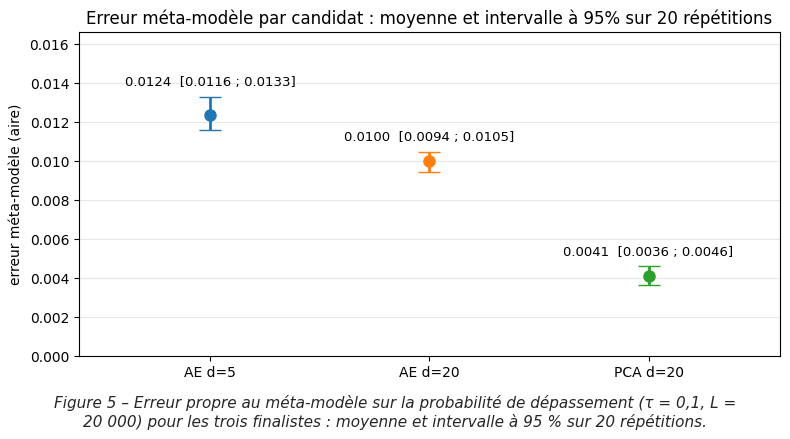

AE d=5 / PCA d=20 : ratio 3.04, IC95 [2.96 ; 3.12], AE d=5 meilleur sur 0% des répétitions, p = 1.9e-06
AE d=20 / PCA d=20 : ratio 2.45, IC95 [2.40 ; 2.52], AE d=20 meilleur sur 0% des répétitions, p = 1.9e-06


In [33]:
# Confirmation sur 20 répétitions : les trois finalistes
finalistes = {'AE d=5': (gpr_store[('AE', 5, 'RBF')], ae_reducers[5].decoder),
              'AE d=20': (gpr_store[('AE', 20, 'RBF')], ae_reducers[20].decoder),
              'PCA d=20': (gpr_store[('PCA', 20, 'RBF')], pca_reducers[20].decoder)}
etude_f = {}
for nom, (g, dec) in finalistes.items():
    etude_f[nom] = pd.DataFrame(mc_error_study(g, dec, x_grid, p_exact, tau, [20000], n_repeats=20,
                                               mu_min=mu_min, mu_max=mu_max, k_shape=k_shape,
                                               theta_scale=theta_scale, gaussian_pdf=gaussian_pdf))
fig = plot_candidates_ci(etude_f)
add_caption(fig, "Erreur propre au méta-modèle sur la probabilité de dépassement (τ = 0,1, L = 20 000) "
                 "pour les trois finalistes : moyenne et intervalle à 95 % sur 20 répétitions.")
plt.show()

for nom in ['AE d=5', 'AE d=20']:
    pc = paired_comparison(etude_f[nom]['erreur méta-modèle'].values,
                           etude_f['PCA d=20']['erreur méta-modèle'].values)
    print(f"{nom} / PCA d=20 : ratio {pc['ratio']:.2f}, IC95 [{pc['ratio_ic95'][0]:.2f} ; "
          f"{pc['ratio_ic95'][1]:.2f}], {nom} meilleur sur {pc['part_a_meilleur']:.0%} des répétitions, "
          f"p = {pc['p_wilcoxon']:.1e}")

In [34]:
import time

g20, dec20 = gpr_store[('PCA', 20, 'RBF')], pca_reducers[20].decoder
n_construction = len(y_train) + len(y_test)                          # 2000 appels au simulateur
t_train = pca_reducers[20].fit_time_ + g20.fit_time_                  # PCA + GPR (s)
t0 = time.perf_counter()
mc_exceedance(g20, dec20, tau, 20000, mu_min, mu_max, k_shape, theta_scale, seed=0)
t_eval = time.perf_counter() - t0                                     # 20 000 courbes par le méta-modèle

def duree(s):
    return f"{s / 86400:.1f} jours" if s > 86400 else f"{s / 3600:.1f} h"

gain = []
for cout, c in [('3 s par appel', 3), ('3 min par appel', 180)]:
    t_direct = 20000 * c
    t_meta = n_construction * c + t_train + t_eval
    gain.append({'coût du simulateur': cout, 'Monte-Carlo direct': duree(t_direct),
                 'méta-modèle (construction + entraînement + évaluation)': duree(t_meta),
                 'facteur de gain': round(t_direct / t_meta, 1)})
print(f"entraînement PCA + GPR : {t_train:.0f} s ; évaluation de 20 000 courbes : {t_eval:.1f} s")
display(pd.DataFrame(gain).set_index('coût du simulateur'))

entraînement PCA + GPR : 208 s ; évaluation de 20 000 courbes : 2.4 s


,Monte-Carlo direct,méta-modèle (construction + entraînement + évaluation),facteur de gain
coût du simulateur,,,
3 s par appel,16.7 h,1.7 h,9.7
3 min par appel,41.7 jours,4.2 jours,10.0


**Gain de temps.** Avec un simulateur à 3 s par appel, estimer $E(x, \tau)$ par Monte-Carlo direct ($L = 20\,000$) prendrait 16,7 h, contre 1,7 h avec le méta-modèle (2 000 appels pour construire le jeu de données, 208 s d'entraînement PCA + GPR, 2,4 s pour évaluer les 20 000 courbes), soit un gain d'un facteur 10 ; à 3 min par appel, 41,7 jours contre 4,2 jours. Ce coût est presque entièrement dû à la construction du jeu de données : une fois le méta-modèle construit, chaque nouvelle estimation (autre seuil, autre $L$, répétitions) ne coûte que quelques secondes. Les études de ce projet ont ainsi évalué environ 4,5 millions de courbes, soit environ cinq mois de calcul avec le simulateur direct à 3 s par appel.

**Q4.1.** Quel méta-modèle recommandez-vous ? Argumentez avec au moins trois critères quantifiés.

**Réponse Q4.1 :**

**Méta-modèle recommandé : PCA ($d = 20$) + GPR (noyau RBF, entrée $(\mu, \log \sigma^2)$).**
1. **Précision sur la probabilité de dépassement**, le critère qui compte pour le projet : son erreur propre en aire vaut $0{,}0041$ (IC à 95 % $[0{,}0036 ; 0{,}0046]$, 20 répétitions, Figure 5), soit 3,0 fois moins que l'AE $d = 5$ et 2,5 fois moins que l'AE $d = 20$, sur les 20 répétitions ($p = 1{,}9 \cdot 10^{-6}$). Son erreur totale ($0{,}0200$) est au niveau du bruit Monte-Carlo seul ($0{,}0203$) : à $L = 20\,000$, il est indiscernable du vrai simulateur.
2. **Qualité de reconstruction** : EQM de $5{,}9 \cdot 10^{-5}$, la meilleure de tous les réducteurs (AE : $1{,}3$ à $1{,}7 \cdot 10^{-4}$), avec un décodeur exact et linéaire.
3. **Erreur de courbe après GPR** : EQM décodée de $1{,}70 \cdot 10^{-4}$, plus faible que tous les AE (meilleur AE : $2{,}05 \cdot 10^{-4}$) ; elle n'est dégradée que par la courbe extrapolée $\sigma^2 = 0{,}029$.
4. **Coût** : aucun réseau à entraîner (PCA en moins d'une seconde, contre 80 à 140 s par AE), mais une GPR plus lente avec 20 sorties (≈ 200 s contre 40 s pour l'AE $d = 5$) ; les deux restent négligeables devant le coût du simulateur.

Ce choix diffère de l'AE retenu en Partie 1 : le critère de reconstruction à petite dimension favorisait l'AE, mais sur la quantité réellement estimée, une PCA avec assez de composantes est plus précise. Ses limites : 20 codes à prédire, des courbes reconstruites parfois légèrement négatives, et une extrapolation fragile pour les $\sigma^2$ plus petits que ceux du train.

---

## Avant de rendre — checklist

- [ ] Toutes les cellules s'exécutent de haut en bas sans erreur (*Kernel → Restart & Run All*).
- [ ] Les fonctions/ classes de fond sont dans `src/*.py` (pas de grosses fonctions dans le notebook).
- [ ] Toutes les questions `Q…` sont traitées dans les cellules « Réponse ».
- [ ] Figures titrées/légendées, graines fixées, choix PyTorch/tensorflow annoncé.
- [ ] Dépôt effectué sur Moodle (notebook + `src/`), **aucun rapport à joindre**.
